# Tarea 2 — Inteligencia Artificial



- Integrantes: Andrés Hormazabal, Héctor Vines.
- Profesor: Johan Fuentes. 
- Ayudantes: Dante Libiot, Miguel Pereira, Matias Vasquez.
- URL del dataset utilizado para la pregunta 1: https://www.kaggle.com/datasets/saichaitanyareddyai/spotify-tracks-dataset-audio-features



## Pregunta 1 — Desarrollo conservado

Esta copia conserva la pregunta 1 y agrega la pregunta 2 al final. Se mantienen los objetivos, las diez predictoras, la semilla 42 y la partición 70/15/15. Se conservan las canciones con popularidad cero que cumplen los restantes filtros. Todos los resultados se recalculan al ejecutar el notebook de principio a fin.

## 0. Configuración y carga de Spotify — Python 3.10

Desde la raíz del proyecto, preparar el entorno aislado con:

```bash
python3.10 -m venv .venv
.venv/bin/python -m pip install -r requirements-py310.txt
```

Seleccionar el intérprete `.venv/bin/python` como kernel del notebook en el editor.
Las versiones de las bibliotecas se fijan en `requirements-py310.txt` para reproducir
la ejecución con Python 3.10. La primera celda muestra las versiones utilizadas.

Se busca el CSV en `data/raw/` desde el directorio del notebook o en
`notebooks/data/raw/` desde la raíz del proyecto. Si no está disponible localmente,
se descarga con `kagglehub`. No se carga el dataset de la pregunta 2.


In [1]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import sklearn
from matplotlib import pyplot as plt
from IPython import get_ipython
from IPython.display import Markdown, display
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    r2_score, mean_squared_error, mean_absolute_error,
    confusion_matrix, ConfusionMatrixDisplay,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# RMSE univariado: alternativa para instalaciones de scikit-learn anteriores a 1.4.
try:
    from sklearn.metrics import root_mean_squared_error
except ImportError:
    def root_mean_squared_error(y_true, y_pred, *, sample_weight=None):
        return float(np.sqrt(mean_squared_error(
            y_true, y_pred, sample_weight=sample_weight
        )))

# Activar inline solo dentro de IPython o Jupyter.
ipython = get_ipython()
if ipython is not None:
    ipython.run_line_magic('matplotlib', 'inline')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': False})
pd.set_option('display.max_columns', 20)
seed = 42

predictorias = [
    'duration_ms', 'danceability', 'energy', 'loudness', 'speechiness',
    'acousticness', 'instrumentalness', 'liveness', 'tempo', 'valence',
]
objetivo_y1 = 'popularity'
objetivo_y2 = 'explicit'
columnas_modelado = predictorias + [objetivo_y1, objetivo_y2]

nombre_csv = 'spotify-tracks-dataset-detailed.csv'
candidatos = [
    Path.cwd() / 'data' / 'raw' / nombre_csv,
    Path.cwd() / 'notebooks' / 'data' / 'raw' / nombre_csv,
]
spotify_file = next((p for p in candidatos if p.is_file()), None)
if spotify_file is None:
    import kagglehub
    directorio = Path(kagglehub.dataset_download(
        'saichaitanyareddyai/spotify-tracks-dataset-audio-features'
    ))
    spotify_file = directorio / nombre_csv

df_spotify = pd.read_csv(spotify_file)
assert set(['track_id'] + columnas_modelado).issubset(df_spotify.columns)
assert df_spotify.shape[0] >= 20_000 and len(columnas_modelado) == 12
assert len(set(predictorias)) == 10
assert objetivo_y1 not in predictorias and objetivo_y2 not in predictorias
print('CSV:', spotify_file)
print('Dataset original:', df_spotify.shape)
print('Python:', sys.version.split()[0])
print('scikit-learn:', sklearn.__version__)

/Users/hectorvines/radioconda/lib/python3.10/site-packages/scipy/__init__.py:132: UserWarning: A NumPy version >=1.21.6 and <1.28.0 is required for this version of SciPy (detected version 2.2.6)
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"

A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.2.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "/Users/hectorvines/radioconda/lib/python3.10/runpy.py", line 196, in _run_module_as_main
    return _run_code(code, main_globals, None,
  File "/Users/hectorvines/radioconda/lib/python3.10/runpy.py", line 86, in _run_code
    exec(code, run_globals)
 

AttributeError: _ARRAY_API not found

ImportError: numpy.core.multiarray failed to import

## 1.0 Dataset y variables

Se utiliza el dataset de pistas de Spotify citado en la portada. Cada registro
describe una pista y sus características musicales. Se abordan dos tareas de
aprendizaje supervisado: estimar su popularidad y clasificar su contenido explícito.


| # | Columna | Descripción | Tipo ||---|---|---|---|
| 0 | track_id | Identificador único de la pista en Spotify | Categórica (texto) |
| 1 | artists | Artista(s) que interpretan la pista, separados por ; | Categórica (texto) |
| 2 | album_name | Nombre del álbum en que aparece la pista | Categórica (texto) |
| 3 | track_name | Nombre de la pista | Categórica (texto) |
| 4 | popularity | Popularidad de la pista (0 a 100), según reproducciones recientes | Numérica discreta |
| 5 | duration_ms | Duración de la pista en milisegundos | Numérica continua |
| 6 | explicit | Indica si la pista tiene contenido explícito | Binaria (booleana) |
| 7 | danceability | Qué tan bailable es la pista (0.0 a 1.0) | Numérica continua |
| 8 | energy | Intensidad y actividad percibida de la pista (0.0 a 1.0) | Numérica continua |
| 9 | key | Tonalidad de la pista (0 = Do, 1 = Do#, ..., 11 = Si) | Categórica (codificada numéricamente) |
| 10 | loudness | Volumen promedio de la pista en decibelios (dB) | Numérica continua |
| 11 | mode | Modalidad de la pista (1 = mayor, 0 = menor) | Binaria |
| 12 | speechiness | Presencia de palabras habladas en la pista (0.0 a 1.0) | Numérica continua |
| 13 | acousticness | Confianza de que la pista sea acústica (0.0 a 1.0) | Numérica continua |
| 14 | instrumentalness | Probabilidad de que la pista no contenga voz (0.0 a 1.0) | Numérica continua |
| 15 | liveness | Probabilidad de que la pista sea una grabación en vivo (0.0 a 1.0) | Numérica continua |
| 16 | valence | Positividad musical transmitida por la pista (0.0 a 1.0) | Numérica continua |
| 17 | tempo | Tempo estimado de la pista en pulsos por minuto (BPM) | Numérica continua |
| 18 | time_signature | Compás estimado de la pista (pulsos por compás) | Numérica discreta |
| 19 | track_genre | Género musical asociado a la pista | Categórica (texto) |

### 1.1 Objetivos y diez predictoras iniciales

Se mantiene **Y₁ = `popularity`** como respuesta cuantitativa de regresión y
**Y₂ = `explicit`** como etiqueta binaria (1: explícita; 0: no explícita).
La popularidad mide alcance, mientras que `explicit` identifica una propiedad del
contenido; son objetivos distintos y requieren selecciones de variables separadas.

Las diez predictoras iniciales son `duration_ms`, `danceability`, `energy`,
`loudness`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`,
`tempo` y `valence`. Se usan exactamente las mismas diez en ambas tareas.

Se excluyen identificadores y texto. También se dejan fuera `key`, `mode` y
`time_signature` para mantener la selección inicial de características continuas:
`key` tiene estructura circular, `mode` es otra variable binaria y el compás es
discreto. La elección de `explicit` se justifica por la tarea de contenido, no por
ser la única variable binaria. Las asociaciones acústicas con ambos objetivos
se investigan empíricamente, sin presuponer que sean nulas ni causales.

### 1.2 Limpieza y división 70/15/15

Se conserva la primera aparición de cada `track_id` para evitar que la misma pista
quede repetida entre particiones. Se mantienen los filtros previos sobre ceros
en `tempo`, `danceability` y `duration_ms`; por tanto, el alcance del estudio
queda limitado a canciones con esas tres características distintas de cero.
Un valor cero no demuestra por sí solo un error, y estos filtros constituyen
una decisión de inclusión heredada, no una prueba de invalidez universal.

**Se retira el filtro de popularidad:** las pistas con `popularity = 0` se
conservan si cumplen los demás criterios. Se verifican explícitamente nulos y
valores finitos en las doce columnas de modelado. Los nulos en texto no usado
no requieren eliminar registros ni imputar información para estos modelos.

In [ ]:
nulos_modelado = df_spotify[columnas_modelado].isna().sum()
display(nulos_modelado.rename('nulos_modelado').to_frame())
assert nulos_modelado.sum() == 0, 'Hay nulos en columnas utilizadas por los modelos.'

df_sin_duplicados = df_spotify.drop_duplicates(subset='track_id', keep='first').copy()
mask_valid = (
    (df_sin_duplicados['tempo'] != 0)
    & (df_sin_duplicados['danceability'] != 0)
    & (df_sin_duplicados['duration_ms'] != 0)
)
df_clean = df_sin_duplicados.loc[mask_valid].copy()
df_clean['explicit'] = df_clean['explicit'].astype(int)

conteos_limpieza = pd.DataFrame({
    'etapa': ['Original', 'Una fila por track_id', 'Filtros tempo/danceability/duración'],
    'filas': [len(df_spotify), len(df_sin_duplicados), len(df_clean)],
})
conteos_limpieza['eliminadas_en_etapa'] = (
    conteos_limpieza['filas'].shift(1) - conteos_limpieza['filas']
).fillna(0).astype(int)
display(conteos_limpieza)

estadisticas = pd.DataFrame({
    'original': df_spotify['popularity'].agg(['count', 'mean', 'std', 'min', 'max']),
    'limpio': df_clean['popularity'].agg(['count', 'mean', 'std', 'min', 'max']),
})
display(estadisticas.round(4))
n_ceros_conservados = int(df_clean['popularity'].eq(0).sum())
assert n_ceros_conservados == int(
    (mask_valid & df_sin_duplicados['popularity'].eq(0)).sum()
)
assert n_ceros_conservados > 0
assert len(df_clean) >= 20_000
assert df_clean['track_id'].is_unique
assert np.isfinite(df_clean[columnas_modelado].to_numpy(dtype=float)).all()
assert set(df_clean['explicit'].unique()) == {0, 1}

display(Markdown(
    f"Se pasa de **{len(df_spotify):,}** a **{len(df_clean):,}** filas. "
    f"Se conservan **{n_ceros_conservados:,}** pistas con popularidad cero. "
    f"La media de popularidad cambia de **{df_spotify['popularity'].mean():.2f}** "
    f"a **{df_clean['popularity'].mean():.2f}** y su desviación muestral de "
    f"**{df_spotify['popularity'].std():.2f}** a **{df_clean['popularity'].std():.2f}**. "
    f"La proporción explícita en la base limpia es **{df_clean['explicit'].mean():.2%}**."
))

,nulos_modelado
duration_ms,0
danceability,0
energy,0
loudness,0
speechiness,0
acousticness,0
instrumentalness,0
liveness,0
tempo,0
valence,0


,etapa,filas,eliminadas_en_etapa
0,Original,114000,0
1,Una fila por track_id,89741,24259
2,Filtros tempo/danceability/duración,89583,158


,original,limpio
count,114000.0000,89583.0000
mean,33.2385,33.1918
std,22.3051,20.5928
min,0.0000,0.0000
max,100.0000,100.0000


Se pasa de **114,000** a **89,583** filas. Se conservan **9,443** pistas con popularidad cero. La media de popularidad cambia de **33.24** a **33.19** y su desviación muestral de **22.31** a **20.59**. La proporción explícita en la base limpia es **8.60%**.

In [ ]:
split_test = 0.15
split_val = 0.15
split_relative_val = split_val / (1 - split_test)

# Mismo procedimiento previo: división aleatoria, sin estratificación.
temp, df_test = train_test_split(df_clean, test_size=split_test, random_state=seed)
df_train, df_val = train_test_split(
    temp, test_size=split_relative_val, random_state=seed
)
particiones = {'train': df_train, 'val': df_val, 'test': df_test}
resumen_particiones = pd.DataFrame([
    {
        'conjunto': nombre,
        'filas': len(datos),
        'proporcion': len(datos) / len(df_clean),
        'media_popularity': datos['popularity'].mean(),
        'desviacion_popularity': datos['popularity'].std(),
        'proporcion_explicit': datos['explicit'].mean(),
    }
    for nombre, datos in particiones.items()
])
display(resumen_particiones.round(6))

ids = {nombre: set(datos['track_id']) for nombre, datos in particiones.items()}
assert sum(map(len, particiones.values())) == len(df_clean)
assert ids['train'].isdisjoint(ids['val'])
assert ids['train'].isdisjoint(ids['test'])
assert ids['val'].isdisjoint(ids['test'])
assert set.union(*ids.values()) == set(df_clean['track_id'])
assert np.allclose(resumen_particiones['proporcion'], [0.70, 0.15, 0.15], atol=2/len(df_clean))
assert all(set(datos['explicit'].unique()) == {0, 1} for datos in particiones.values())
print('Particiones completas, sin pistas compartidas y con ambas clases presentes.')

,conjunto,filas,proporcion,media_popularity,desviacion_popularity,proporcion_explicit
0,train,62707,0.699988,33.210359,20.609690,0.086035
1,val,13438,0.150006,33.267971,20.649987,0.086397
2,test,13438,0.150006,33.029022,20.456887,0.085429


Particiones completas, sin pistas compartidas y con ambas clases presentes.


## 1.A — Regresión lineal para `popularity`

### 1.A.1 Selección de variables con entrenamiento

Se ordenan las diez predictoras por el valor absoluto de su correlación de Pearson
con `popularity` en `df_train`; se conserva el signo para interpretar la dirección.
Ante un empate exacto se ordena alfabéticamente. Los primeros cinco y tres
elementos definen subconjuntos anidados. Pearson describe asociación lineal
individual: no identifica causalidad, relaciones no lineales ni contribuciones
condicionales. La correlación individual máxima no fija un techo para el R²
de una regresión multivariada.

In [ ]:
correlacion_y1 = df_train[predictorias].corrwith(df_train[objetivo_y1])
ranking_y1 = (
    pd.DataFrame({
        'variable': correlacion_y1.index,
        'correlacion': correlacion_y1.to_numpy(),
        'abs_correlacion': correlacion_y1.abs().to_numpy(),
    })
    .sort_values(['abs_correlacion', 'variable'], ascending=[False, True], kind='stable')
    .reset_index(drop=True)
)
assert ranking_y1['correlacion'].notna().all()
listFive = ranking_y1['variable'].head(5).tolist()
listThree = ranking_y1['variable'].head(3).tolist()
configs = {'complete': predictorias.copy(), 'reduce': listFive, 'min': listThree}
assert set(listThree) <= set(listFive) <= set(predictorias)
display(ranking_y1.round(6))
display(Markdown(
    '**Cinco variables:** ' + ', '.join(listFive) + '.\n\n'
    '**Tres variables:** ' + ', '.join(listThree) + '.\n\n'
    'La selección es empírica y univariada: prioriza asociaciones individuales con '
    'la popularidad. No implica que las variables descartadas carezcan de aportes '
    'cuando se combinan con otras.'
))

,variable,correlacion,abs_correlacion
0,instrumentalness,-0.129150,0.129150
1,loudness,0.075280,0.075280
2,danceability,0.066621,0.066621
3,speechiness,-0.045205,0.045205
4,acousticness,-0.040929,0.040929
5,duration_ms,-0.023108,0.023108
6,energy,0.017335,0.017335
7,liveness,-0.015712,0.015712
8,tempo,0.010611,0.010611
9,valence,-0.008018,0.008018


**Cinco variables:** instrumentalness, loudness, danceability, speechiness, acousticness.

**Tres variables:** instrumentalness, loudness, danceability.

La selección es empírica y univariada: prioriza asociaciones individuales con la popularidad. No implica que las variables descartadas carezcan de aportes cuando se combinan con otras.

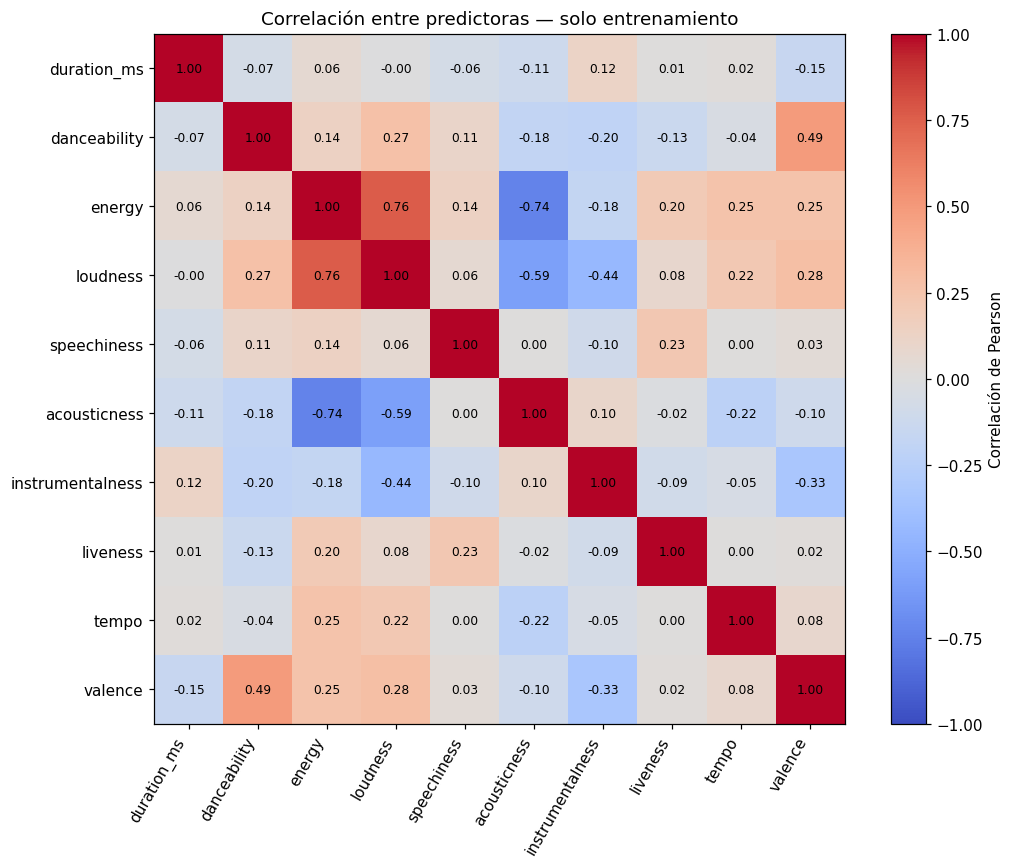

In [ ]:
corr_predictoras = df_train[predictorias].corr()
fig, ax = plt.subplots(figsize=(10, 8))
imagen = ax.imshow(corr_predictoras, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(10), predictorias, rotation=60, ha='right')
ax.set_yticks(range(10), predictorias)
for i in range(10):
    for j in range(10):
        ax.text(j, i, f'{corr_predictoras.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(imagen, ax=ax, label='Correlación de Pearson')
ax.set_title('Correlación entre predictoras — solo entrenamiento')
plt.tight_layout()
plt.show()

### 1.A.2 Entrenamiento de las versiones de 10, 5 y 3 variables

Cada versión ajusta un `StandardScaler` y una `LinearRegression` dentro de un
pipeline usando únicamente entrenamiento. El modelo es

\[
\hat y = \theta_0 + \sum_{j=1}^{p}\theta_j z_j,
\qquad J(\theta)=\frac{1}{2m}\sum_{i=1}^{m}(\hat y^{(i)}-y^{(i)})^2,
\]

donde \(z_j\) es la característica estandarizada. Para estos datos densos,
`LinearRegression` resuelve mínimos cuadrados mediante `lstsq`, sin calcular
explícitamente la inversa de \(X^\top X\). La expresión de la ecuación normal
es una formulación teórica cuando la matriz es invertible; no describe literalmente
la implementación de `.fit()`.

Los coeficientes mostrados corresponden a un aumento de una desviación estándar
de la predictora, manteniendo las demás fijas. La estandarización permite comparar
escalas, pero no elimina multicolinealidad ni otorga interpretación causal.

In [ ]:
def evaluar_regresion(y_real, pred):
    return {
        'R2': r2_score(y_real, pred),
        'RMSE': root_mean_squared_error(y_real, pred),
        'MAE': mean_absolute_error(y_real, pred),
    }

y1_train = df_train[objetivo_y1]
y1_val = df_val[objetivo_y1]
models = {}
results = []
parametros_y1 = []

for version, cols in configs.items():
    pipe = make_pipeline(StandardScaler(), LinearRegression())
    pipe.fit(df_train[cols], y1_train)
    models[version] = pipe
    fila = {'version': version, 'n_vars': len(cols)}
    for conjunto, datos, objetivo in [
        ('train', df_train, y1_train), ('val', df_val, y1_val)
    ]:
        metricas = evaluar_regresion(objetivo, pipe.predict(datos[cols]))
        fila.update({f'{metrica}_{conjunto}': valor for metrica, valor in metricas.items()})
    results.append(fila)
    ajuste = pipe.named_steps['linearregression']
    parametros_y1.append({'version': version, 'variable': 'intercepto', 'coeficiente': ajuste.intercept_})
    parametros_y1.extend(
        {'version': version, 'variable': col, 'coeficiente': coef}
        for col, coef in zip(cols, ajuste.coef_)
    )

table = pd.DataFrame(results)
display(pd.DataFrame(parametros_y1).round(6))

,version,variable,coeficiente
0,complete,intercepto,33.210359
1,complete,duration_ms,-0.446926
2,complete,danceability,1.817208
3,complete,energy,-0.452697
4,complete,loudness,0.470365
5,complete,speechiness,-1.325627
6,complete,acousticness,-0.499330
7,complete,instrumentalness,-2.898726
8,complete,liveness,0.015595
9,complete,tempo,0.237744


### 1.A.3 Comparación en entrenamiento y validación

Se reportan R² (mayor es mejor), RMSE y MAE (menor es mejor, en puntos de
popularidad). R² puede ser negativo si el modelo es peor que la referencia
de la media del conjunto evaluado. Como baseline predictivo se ajusta un
`DummyRegressor` con la media de **entrenamiento**, aplicando esa misma constante
a validación. La referencia no aprende la media de validación.

In [ ]:
baseline_y1 = DummyRegressor(strategy='mean').fit(df_train[predictorias], y1_train)
filas_baseline_y1 = []
for conjunto, datos, objetivo in [
    ('train', df_train, y1_train), ('val', df_val, y1_val)
]:
    filas_baseline_y1.append({
        'conjunto': conjunto,
        **evaluar_regresion(objetivo, baseline_y1.predict(datos[predictorias])),
    })
tabla_baseline_y1 = pd.DataFrame(filas_baseline_y1).set_index('conjunto')
table['brecha_R2'] = table['R2_train'] - table['R2_val']
display(table.round(6))
display(tabla_baseline_y1.round(6))

# La identidad usa varianza poblacional del mismo conjunto, no std() con ddof=1.
for conjunto, objetivo in [('train', y1_train), ('val', y1_val)]:
    varianza = objetivo.var(ddof=0)
    assert np.allclose(table[f'R2_{conjunto}'], 1 - table[f'RMSE_{conjunto}']**2 / varianza)
    assert (table[f'RMSE_{conjunto}'] >= table[f'MAE_{conjunto}'] - 1e-10).all()
assert (np.diff(table['R2_train']) <= 1e-10).all()

orden_y1 = table.sort_values(
    ['R2_val', 'n_vars', 'version'], ascending=[False, True, True], kind='stable'
)
mejores_y1 = orden_y1['version'].head(2).tolist()
res_y1 = table.set_index('version')
mejor_y1 = orden_y1.iloc[0]
rmse_baseline_val = tabla_baseline_y1.loc['val', 'RMSE']
mejora_rmse_y1 = 1 - mejor_y1['RMSE_val'] / rmse_baseline_val
caida_10_5 = res_y1.loc['complete', 'R2_val'] - res_y1.loc['reduce', 'R2_val']
caida_5_3 = res_y1.loc['reduce', 'R2_val'] - res_y1.loc['min', 'R2_val']
brechas_y1 = '; '.join(
    f"{fila.version}: {fila.brecha_R2:.5f}" for fila in table.itertuples()
)
display(Markdown(f"""
**Nivel de desempeño.** La mejor versión en validación es **{mejor_y1['version']}**,
con R² = **{mejor_y1['R2_val']:.4f}**, RMSE = **{mejor_y1['RMSE_val']:.3f}** y
MAE = **{mejor_y1['MAE_val']:.3f}**. El baseline de media obtiene RMSE =
**{rmse_baseline_val:.3f}**; la reducción relativa de RMSE es **{mejora_rmse_y1:.2%}**.
Esta referencia permite valorar el aporte del modelo sin confundir estabilidad
entre conjuntos con alta capacidad predictiva.

**Generalización.** Las brechas R² de entrenamiento menos validación son
**{brechas_y1}**. En la versión completa, R² es
**{mejor_y1['R2_train']:.4f}** en entrenamiento y **{mejor_y1['R2_val']:.4f}**
en validación: no aparece una ventaja marcada del entrenamiento. El R² bajo
en ambos y la mejora de RMSE de **{mejora_rmse_y1:.2%}** frente a la media
muestran capacidad predictiva limitada con estas características y este modelo.
La cercanía entre conjuntos no basta para identificar la causa de esa limitación.

**Cantidad de variables.** El cambio de R² en validación al pasar de 10 a 5 es
**{caida_10_5:+.5f}**, y de 5 a 3 es **{caida_5_3:+.5f}** (valor positivo indica
caída). Reducir variables modifica tanto la complejidad como la información
disponible. En esta partición las tres métricas de validación favorecen conservar
las diez variables; la pérdida de R² de 10 a 5 es mayor que la de 5 a 3.
El ranking univariado no garantiza conservar las mejores combinaciones y puede
descartar variables que aportan información condicional. Las diferencias
observadas no establecen una regla general para otras particiones.

**Selección fijada antes de prueba:** mayor R² en validación; ante empate exacto,
menor cantidad de variables y luego nombre de versión. Las versiones elegidas son
**{', '.join(mejores_y1)}**.
"""))

,version,n_vars,R2_train,RMSE_train,MAE_train,R2_val,RMSE_val,MAE_val,brecha_R2
0,complete,10,0.030716,20.290534,16.714511,0.032589,20.309968,16.749437,-0.001872
1,reduce,5,0.022696,20.374310,16.864474,0.022692,20.413585,16.908450,0.000003
2,min,3,0.018605,20.416903,16.977155,0.018456,20.457777,17.024529,0.000149


,R2,RMSE,MAE
conjunto,,,
train,0.000000,20.609526,17.262552
val,-0.000008,20.649299,17.276791



**Nivel de desempeño.** La mejor versión en validación es **complete**,
con R² = **0.0326**, RMSE = **20.310** y
MAE = **16.749**. El baseline de media obtiene RMSE =
**20.649**; la reducción relativa de RMSE es **1.64%**.
Esta referencia permite valorar el aporte del modelo sin confundir estabilidad
entre conjuntos con alta capacidad predictiva.

**Generalización.** Las brechas R² de entrenamiento menos validación son
**complete: -0.00187; reduce: 0.00000; min: 0.00015**. En la versión completa, R² es
**0.0307** en entrenamiento y **0.0326**
en validación: no aparece una ventaja marcada del entrenamiento. El R² bajo
en ambos y la mejora de RMSE de **1.64%** frente a la media
muestran capacidad predictiva limitada con estas características y este modelo.
La cercanía entre conjuntos no basta para identificar la causa de esa limitación.

**Cantidad de variables.** El cambio de R² en validación al pasar de 10 a 5 es
**+0.00990**, y de 5 a 3 es **+0.00424** (valor positivo indica
caída). Reducir variables modifica tanto la complejidad como la información
disponible. En esta partición las tres métricas de validación favorecen conservar
las diez variables; la pérdida de R² de 10 a 5 es mayor que la de 5 a 3.
El ranking univariado no garantiza conservar las mejores combinaciones y puede
descartar variables que aportan información condicional. Las diferencias
observadas no establecen una regla general para otras particiones.

**Selección fijada antes de prueba:** mayor R² en validación; ante empate exacto,
menor cantidad de variables y luego nombre de versión. Las versiones elegidas son
**complete, reduce**.


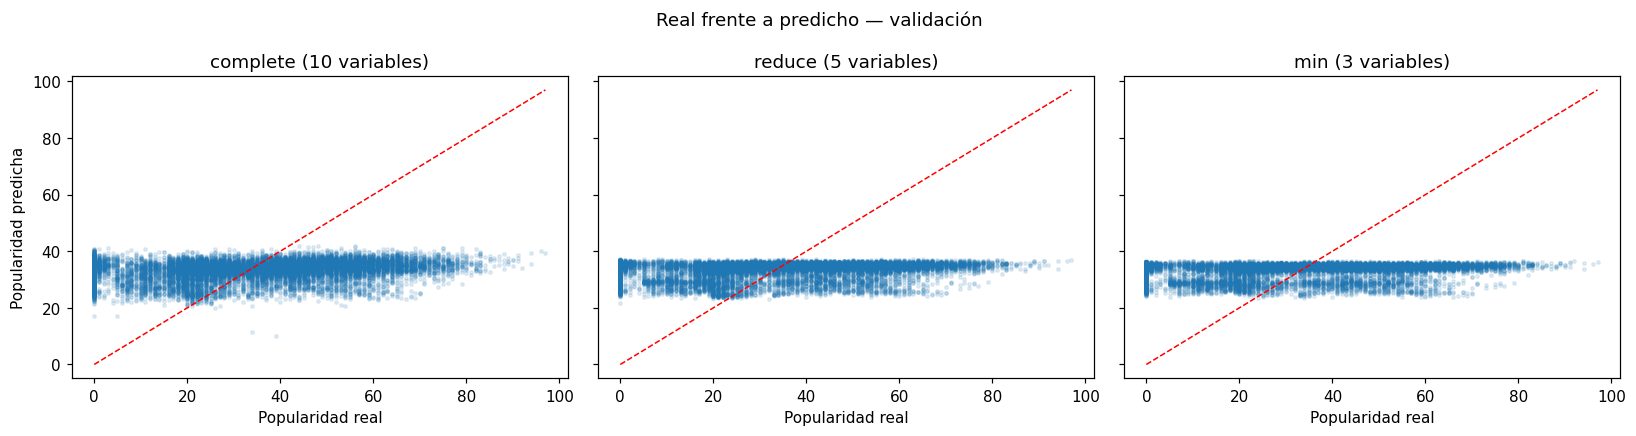

In [ ]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
for ax, (version, cols) in zip(ejes, configs.items()):
    pred = models[version].predict(df_val[cols])
    ax.scatter(y1_val, pred, s=5, alpha=0.12)
    limites = [min(y1_val.min(), pred.min()), max(y1_val.max(), pred.max())]
    ax.plot(limites, limites, 'r--', linewidth=1)
    ax.set_title(f'{version} ({len(cols)} variables)')
    ax.set_xlabel('Popularidad real')
ejes[0].set_ylabel('Popularidad predicha')
fig.suptitle('Real frente a predicho — validación')
plt.tight_layout()
plt.show()

### 1.A.4 Prueba de las dos mejores versiones lineales

Las versiones ya se eligieron en validación. Se aplican los pipelines entrenados,
sin ejecutar `.fit()` ni modificar columnas o parámetros después de ver prueba.

In [ ]:
y1_test = df_test[objetivo_y1]
tabla_test_y1 = pd.DataFrame([
    {
        'version': version,
        'n_vars': len(configs[version]),
        **{f'{metrica}_test': valor for metrica, valor in evaluar_regresion(
            y1_test, models[version].predict(df_test[configs[version]])
        ).items()},
    }
    for version in mejores_y1
])
comparacion_test_y1 = tabla_test_y1.merge(
    table[['version', 'R2_val', 'RMSE_val', 'MAE_val']], on='version', validate='one_to_one'
)
comparacion_test_y1['cambio_R2_test_val'] = (
    comparacion_test_y1['R2_test'] - comparacion_test_y1['R2_val']
)
display(comparacion_test_y1.round(6))
detalle_prueba_y1 = '; '.join(
    f"{f.version}: R² validación {f.R2_val:.4f}, prueba {f.R2_test:.4f} "
    f"(cambio {f.cambio_R2_test_val:+.4f})"
    for f in comparacion_test_y1.itertuples()
)
display(Markdown(
    '**Contraste con validación.** ' + detalle_prueba_y1 + '. '
    'La diferencia estima la variación entre estas particiones; una sola división '
    'no proporciona intervalos de incertidumbre ni demuestra estabilidad en otras poblaciones. '
    'Los resultados de prueba se reportan sin usarlos para revisar la selección.'
))

,version,n_vars,R2_test,RMSE_test,MAE_test,R2_val,RMSE_val,MAE_val,cambio_R2_test_val
0,complete,10,0.032671,20.119189,16.589625,0.032589,20.309968,16.749437,0.000083
1,reduce,5,0.022793,20.221657,16.763151,0.022692,20.413585,16.908450,0.000100


**Contraste con validación.** complete: R² validación 0.0326, prueba 0.0327 (cambio +0.0001); reduce: R² validación 0.0227, prueba 0.0228 (cambio +0.0001). La diferencia estima la variación entre estas particiones; una sola división no proporciona intervalos de incertidumbre ni demuestra estabilidad en otras poblaciones. Los resultados de prueba se reportan sin usarlos para revisar la selección.

## 1.B — Regresión logística para `explicit`

### 1.B.1 Selección de variables con entrenamiento

Se calcula, para cada predictora, la diferencia absoluta entre su media en la
clase 1 y en la clase 0, dividida por su desviación estándar muestral en todo
entrenamiento. La estandarización evita que las unidades dominen el ranking.
Los empates exactos se resuelven alfabéticamente. Las listas de cinco y tres
variables se obtienen de este ranking nuevo y usan nombres distintos a las de Y₁.

El criterio mide separación de medias y puede omitir relaciones que no cambian
el promedio. Es una selección univariada, no una garantía de la mejor combinación.
Pearson con una etiqueta binaria equivale a la correlación punto-biserial y también
es válido para describir esa asociación; no se descarta por el tipo binario.

In [ ]:
y2_train = df_train[objetivo_y2]
y2_val = df_val[objetivo_y2]
medias_y2 = df_train.groupby(objetivo_y2)[predictorias].mean()
desviaciones_y2 = df_train[predictorias].std(ddof=1)
assert (desviaciones_y2 > 0).all(), 'El ranking requiere predictoras no constantes.'
diferencias_y2 = medias_y2.loc[1] - medias_y2.loc[0]
ranking_y2 = pd.DataFrame({
    'variable': predictorias,
    'media_no_explicita': medias_y2.loc[0, predictorias].to_numpy(),
    'media_explicita': medias_y2.loc[1, predictorias].to_numpy(),
    'diferencia_con_signo': diferencias_y2.loc[predictorias].to_numpy(),
    'desviacion_train': desviaciones_y2.loc[predictorias].to_numpy(),
    'puntaje': (diferencias_y2.abs() / desviaciones_y2).loc[predictorias].to_numpy(),
}).sort_values(['puntaje', 'variable'], ascending=[False, True], kind='stable').reset_index(drop=True)

lista_5_y2 = ranking_y2['variable'].head(5).tolist()
lista_3_y2 = ranking_y2['variable'].head(3).tolist()
configs_y2 = {'complete': predictorias.copy(), 'reduce': lista_5_y2, 'min': lista_3_y2}
assert set(lista_3_y2) <= set(lista_5_y2) <= set(predictorias)
assert configs['reduce'] == listFive and configs['min'] == listThree
display(ranking_y2.round(6))

sentido_variables = {
    'duration_ms': 'la duración describe la extensión de la pista, sin indicar por sí sola el lenguaje utilizado',
    'danceability': 'la bailabilidad puede recoger asociaciones con estilos y repertorios',
    'energy': 'la energía caracteriza intensidad acústica y posibles diferencias entre repertorios',
    'loudness': 'el volumen medio recoge diferencias de producción y estilo',
    'speechiness': 'la presencia de habla describe material vocal, potencialmente relacionado con el contenido verbal',
    'acousticness': 'el carácter acústico puede distinguir estilos presentes con distinta frecuencia en cada clase',
    'instrumentalness': 'la ausencia de voz puede asociarse con una menor presencia de lenguaje explícito',
    'liveness': 'el carácter en vivo describe el contexto de grabación y puede actuar como asociación indirecta',
    'tempo': 'el tempo caracteriza patrones rítmicos, con una relación posible e indirecta con el repertorio',
    'valence': 'la valencia describe el carácter musical percibido, no el significado literal de la letra',
}
justificacion_y2 = '\n'.join(
    f"- **{variable}:** {sentido_variables[variable]}." for variable in lista_5_y2
)
display(Markdown(
    '**Cinco variables:** ' + ', '.join(lista_5_y2) + '.\n\n'
    '**Tres variables:** ' + ', '.join(lista_3_y2) + '.\n\n'
    '**Pertinencia conceptual de las seleccionadas:**\n\n' + justificacion_y2
    + '\n\nEstas conexiones son explicaciones posibles de asociaciones; el dataset '
    'no contiene letras ni permite establecer causalidad. La justificación empírica '
    'es el puntaje mostrado en la tabla. La coincidencia eventual con el ranking '
    'de Y₁ no invalidaría el procedimiento: lo importante es calcularlo contra Y₂.'
))

,variable,media_no_explicita,media_explicita,diferencia_con_signo,desviacion_train,puntaje
0,speechiness,0.076201,0.208471,0.132269,0.112947,1.171072
1,danceability,0.556055,0.629546,0.073491,0.175328,0.419161
2,instrumentalness,0.184492,0.054454,-0.130038,0.323907,0.401467
3,loudness,-8.665773,-6.601828,2.063945,5.198618,0.397018
4,energy,0.627032,0.720494,0.093462,0.255929,0.365186
5,acousticness,0.336660,0.226005,-0.110655,0.338193,0.327194
6,duration_ms,231238.335392,205405.291566,-25833.043826,108148.011290,0.238867
7,liveness,0.213941,0.241731,0.027790,0.193941,0.143292
8,tempo,122.335968,121.676397,-0.659571,29.720829,0.022192
9,valence,0.469498,0.468583,-0.000915,0.262406,0.003487


**Cinco variables:** speechiness, danceability, instrumentalness, loudness, energy.

**Tres variables:** speechiness, danceability, instrumentalness.

**Pertinencia conceptual de las seleccionadas:**

- **speechiness:** la presencia de habla describe material vocal, potencialmente relacionado con el contenido verbal.
- **danceability:** la bailabilidad puede recoger asociaciones con estilos y repertorios.
- **instrumentalness:** la ausencia de voz puede asociarse con una menor presencia de lenguaje explícito.
- **loudness:** el volumen medio recoge diferencias de producción y estilo.
- **energy:** la energía caracteriza intensidad acústica y posibles diferencias entre repertorios.

Estas conexiones son explicaciones posibles de asociaciones; el dataset no contiene letras ni permite establecer causalidad. La justificación empírica es el puntaje mostrado en la tabla. La coincidencia eventual con el ranking de Y₁ no invalidaría el procedimiento: lo importante es calcularlo contra Y₂.

### 1.B.2 Entrenamiento de las versiones de 10, 5 y 3 variables

La regresión logística estima
\(P(Y_2=1\mid z)=1/(1+e^{-(\theta_0+\theta^\top z)})\).
Su ajuste minimiza una pérdida logística con regularización L2. Se mantiene
`C=1`, `solver='lbfgs'`, `max_iter=1000` y `class_weight=None` en las tres versiones.
L-BFGS es un método cuasi-Newton, no el descenso de gradiente elemental.
El escalamiento se aprende dentro de cada pipeline solo con entrenamiento.

Se utiliza el umbral predeterminado de 0,5 para obtener clases mediante `predict`.
ROC-AUC usa las probabilidades de la clase 1, no esas clases discretizadas.
No se buscan hiperparámetros, pesos ni umbrales adicionales en esta etapa.
La métrica decisora será F1 de la clase positiva; los desempates usarán ROC-AUC,
menor número de variables y, finalmente, nombre de versión.

In [ ]:
modelos_y2 = {}
for version, cols in configs_y2.items():
    pipe = make_pipeline(
        StandardScaler(),
        LogisticRegression(solver='lbfgs', C=1.0, max_iter=1000, class_weight=None),
    )
    with warnings.catch_warnings():
        warnings.simplefilter('error', ConvergenceWarning)
        pipe.fit(df_train[cols], y2_train)
    modelos_y2[version] = pipe
    print(version, ':', len(cols), 'variables; iteraciones:',
          pipe.named_steps['logisticregression'].n_iter_.tolist())

complete : 10 variables; iteraciones: [13]
reduce : 5 variables; iteraciones: [11]
min : 3 variables; iteraciones: [10]


### 1.B.3 Comparación en entrenamiento y validación

Se considera positiva la clase `explicit = 1`. Precisión mide el acierto entre
las predicciones positivas; recall mide la fracción de positivos reales detectados;
F1 combina ambas. Si no se predicen positivos, se reporta cero mediante
`zero_division=0`, junto con la matriz que permite reconocer ese comportamiento.

Accuracy se interpreta frente a un clasificador que siempre responde la clase
mayoritaria aprendida en entrenamiento. ROC-AUC describe ordenamiento de las
probabilidades y no garantiza un buen desempeño en el umbral 0,5. Se reportan
las cinco métricas para ambos conjuntos y las matrices de las tres versiones.

In [ ]:
def evaluar_clasificacion(y_real, pred, proba_positiva):
    return {
        'accuracy': accuracy_score(y_real, pred),
        'precision': precision_score(y_real, pred, pos_label=1, zero_division=0),
        'recall': recall_score(y_real, pred, pos_label=1, zero_division=0),
        'f1': f1_score(y_real, pred, pos_label=1, zero_division=0),
        'auc': roc_auc_score(y_real, proba_positiva),
    }

def probabilidad_positiva(estimador, X):
    columna_positiva = list(estimador.classes_).index(1)
    return estimador.predict_proba(X)[:, columna_positiva]

filas_clases = []
for conjunto, objetivo in [('train', y2_train), ('val', y2_val)]:
    for clase, conteo in objetivo.value_counts().sort_index().items():
        filas_clases.append({
            'conjunto': conjunto, 'clase': clase,
            'filas': conteo, 'proporcion': conteo / len(objetivo),
        })
tabla_clases_y2 = pd.DataFrame(filas_clases)
display(tabla_clases_y2.round(6))

resultados_y2 = []
matrices_y2 = {}
for version, cols in configs_y2.items():
    pipe = modelos_y2[version]
    fila = {'version': version, 'n_vars': len(cols)}
    for conjunto, datos, objetivo in [
        ('train', df_train, y2_train), ('val', df_val, y2_val)
    ]:
        pred = pipe.predict(datos[cols])
        proba = probabilidad_positiva(pipe, datos[cols])
        metricas = evaluar_clasificacion(objetivo, pred, proba)
        fila.update({f'{metrica}_{conjunto}': valor for metrica, valor in metricas.items()})
        matrices_y2[(version, conjunto)] = confusion_matrix(objetivo, pred, labels=[0, 1])
    fila['brecha_f1'] = fila['f1_train'] - fila['f1_val']
    fila['brecha_auc'] = fila['auc_train'] - fila['auc_val']
    resultados_y2.append(fila)

tabla_y2 = pd.DataFrame(resultados_y2)
display(tabla_y2.round(6))
baseline_y2 = DummyClassifier(strategy='most_frequent').fit(df_train[predictorias], y2_train)
tabla_baseline_y2 = pd.DataFrame([
    {
        'conjunto': conjunto,
        **evaluar_clasificacion(
            objetivo, baseline_y2.predict(datos[predictorias]),
            probabilidad_positiva(baseline_y2, datos[predictorias]),
        ),
    }
    for conjunto, datos, objetivo in [('train', df_train, y2_train), ('val', df_val, y2_val)]
]).set_index('conjunto')
display(tabla_baseline_y2.round(6))

orden_y2 = tabla_y2.sort_values(
    ['f1_val', 'auc_val', 'n_vars', 'version'],
    ascending=[False, False, True, True], kind='stable',
)
mejores_y2 = orden_y2['version'].head(2).tolist()
mejor_y2 = orden_y2.iloc[0]
mejor_version_y2 = mejor_y2['version']
vn, fp, fn, vp = matrices_y2[(mejor_version_y2, 'val')].ravel()
res_y2 = tabla_y2.set_index('version')
caida_f1_10_5 = res_y2.loc['complete', 'f1_val'] - res_y2.loc['reduce', 'f1_val']
caida_f1_5_3 = res_y2.loc['reduce', 'f1_val'] - res_y2.loc['min', 'f1_val']
version_mayor_accuracy = tabla_y2.sort_values(
    ['accuracy_val', 'n_vars', 'version'], ascending=[False, True, True], kind='stable'
).iloc[0]
display(Markdown(f"""
**Desbalance y referencia.** La proporción positiva en validación es
**{y2_val.mean():.2%}**. El baseline mayoritario obtiene accuracy
**{tabla_baseline_y2.loc['val', 'accuracy']:.2%}**, F1
**{tabla_baseline_y2.loc['val', 'f1']:.4f}** y recall
**{tabla_baseline_y2.loc['val', 'recall']:.4f}**. Por ello, accuracy debe leerse
junto a la capacidad de detectar contenido explícito.

**Mejor versión según el criterio fijado.** **{mejor_version_y2}** obtiene en
validación precisión **{mejor_y2['precision_val']:.4f}**, recall
**{mejor_y2['recall_val']:.4f}**, F1 **{mejor_y2['f1_val']:.4f}** y ROC-AUC
**{mejor_y2['auc_val']:.4f}**. Su matriz contiene **{vn:,} VN**, **{fp:,} FP**,
**{fn:,} FN** y **{vp:,} VP**. F1 se prioriza porque interesa recuperar la clase
explícita sin ignorar la precisión de esas detecciones, manteniendo el umbral 0,5.
La proporción de positivos reales no detectados es **{fn / (fn + vp):.2%}**:
la recuperación sigue siendo limitada pese a superar al baseline.

La mayor accuracy de validación corresponde a **{version_mayor_accuracy['version']}**
(**{version_mayor_accuracy['accuracy_val']:.2%}**), cuyo F1 es
**{version_mayor_accuracy['f1_val']:.4f}**. Esa diferencia de orden muestra por qué
la métrica de selección debe reflejar la detección de la clase positiva y no
solo el acierto global dominado por las canciones no explícitas.

**Generalización y reducción.** Para esa versión, la brecha F1 de entrenamiento
menos validación es **{mejor_y2['brecha_f1']:+.5f}**, y la brecha ROC-AUC es
**{mejor_y2['brecha_auc']:+.5f}**. Las caídas de F1 en validación al pasar de
10 a 5 y de 5 a 3 variables son **{caida_f1_10_5:+.5f}** y
**{caida_f1_5_3:+.5f}**, respectivamente. Los efectos sobre F1 y AUC pueden diferir:
una mide decisiones a un umbral fijo y la otra el ordenamiento de probabilidades.

Las dos versiones seleccionadas antes de consultar prueba son
**{', '.join(mejores_y2)}**. No se modifica el umbral para mejorar estos resultados.
"""))

,conjunto,clase,filas,proporcion
0,train,0,57312,0.913965
1,train,1,5395,0.086035
2,val,0,12277,0.913603
3,val,1,1161,0.086397


,version,n_vars,accuracy_train,precision_train,recall_train,f1_train,auc_train,accuracy_val,precision_val,recall_val,f1_val,auc_val,brecha_f1,brecha_auc
0,complete,10,0.915241,0.537037,0.107507,0.179151,0.817292,0.914124,0.513619,0.113695,0.186178,0.829415,-0.007027,-0.012123
1,reduce,5,0.915767,0.570361,0.084893,0.147790,0.783246,0.915240,0.559140,0.089578,0.154417,0.789141,-0.006628,-0.005895
2,min,3,0.915863,0.578393,0.081372,0.142671,0.767826,0.915389,0.568182,0.086133,0.149589,0.778885,-0.006917,-0.011059


,accuracy,precision,recall,f1,auc
conjunto,,,,,
train,0.913965,0.0,0.0,0.0,0.5
val,0.913603,0.0,0.0,0.0,0.5



**Desbalance y referencia.** La proporción positiva en validación es
**8.64%**. El baseline mayoritario obtiene accuracy
**91.36%**, F1
**0.0000** y recall
**0.0000**. Por ello, accuracy debe leerse
junto a la capacidad de detectar contenido explícito.

**Mejor versión según el criterio fijado.** **complete** obtiene en
validación precisión **0.5136**, recall
**0.1137**, F1 **0.1862** y ROC-AUC
**0.8294**. Su matriz contiene **12,152 VN**, **125 FP**,
**1,029 FN** y **132 VP**. F1 se prioriza porque interesa recuperar la clase
explícita sin ignorar la precisión de esas detecciones, manteniendo el umbral 0,5.
La proporción de positivos reales no detectados es **88.63%**:
la recuperación sigue siendo limitada pese a superar al baseline.

La mayor accuracy de validación corresponde a **min**
(**91.54%**), cuyo F1 es
**0.1496**. Esa diferencia de orden muestra por qué
la métrica de selección debe reflejar la detección de la clase positiva y no
solo el acierto global dominado por las canciones no explícitas.

**Generalización y reducción.** Para esa versión, la brecha F1 de entrenamiento
menos validación es **-0.00703**, y la brecha ROC-AUC es
**-0.01212**. Las caídas de F1 en validación al pasar de
10 a 5 y de 5 a 3 variables son **+0.03176** y
**+0.00483**, respectivamente. Los efectos sobre F1 y AUC pueden diferir:
una mide decisiones a un umbral fijo y la otra el ordenamiento de probabilidades.

Las dos versiones seleccionadas antes de consultar prueba son
**complete, reduce**. No se modifica el umbral para mejorar estos resultados.


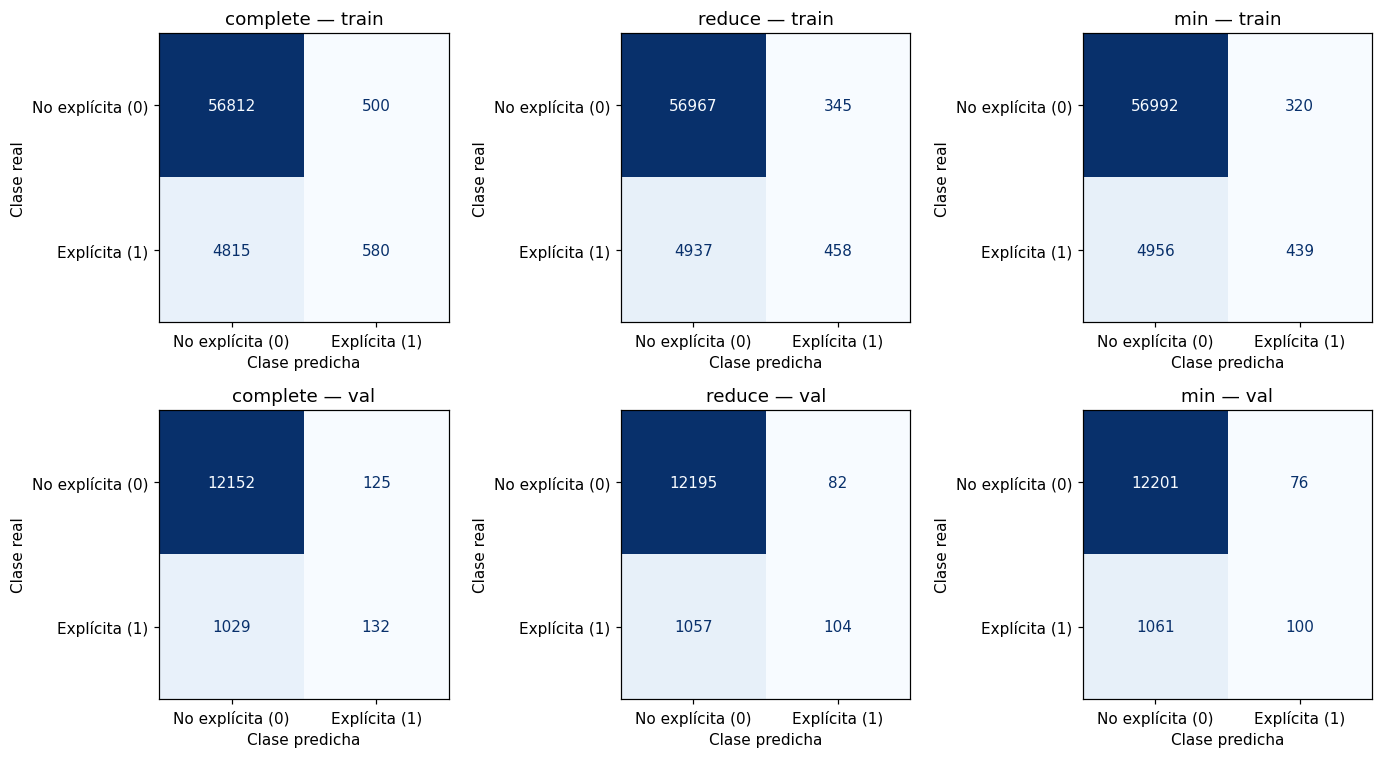

In [ ]:
fig, ejes = plt.subplots(2, 3, figsize=(13, 7))
for fila, conjunto in enumerate(['train', 'val']):
    for columna, version in enumerate(configs_y2):
        ConfusionMatrixDisplay(
            confusion_matrix=matrices_y2[(version, conjunto)],
            display_labels=['No explícita (0)', 'Explícita (1)'],
        ).plot(ax=ejes[fila, columna], colorbar=False, cmap='Blues', values_format='d')
        ejes[fila, columna].set_title(f'{version} — {conjunto}')
        ejes[fila, columna].set_xlabel('Clase predicha')
        ejes[fila, columna].set_ylabel('Clase real')
plt.tight_layout()
plt.show()

### 1.B.4 Prueba de las dos mejores versiones logísticas

Se aplican exclusivamente las dos versiones seleccionadas por F1 de validación,
con los desempates ya declarados. Los modelos, columnas y umbral permanecen
fijados. Se reportan métricas y matrices de confusión sin volver a entrenar.

,version,n_vars,accuracy_test,precision_test,recall_test,f1_test,auc_test,f1_val,auc_val,cambio_f1_test_val,cambio_auc_test_val
0,complete,10,0.916059,0.544248,0.107143,0.179039,0.808654,0.186178,0.829415,-0.007138,-0.020761
1,reduce,5,0.915910,0.554217,0.080139,0.140030,0.771338,0.154417,0.789141,-0.014387,-0.017803


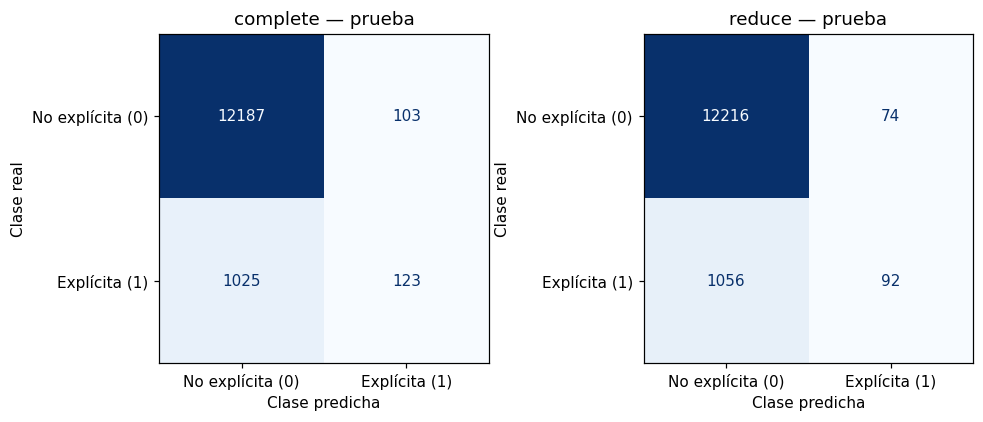

**Contraste con validación.** complete: F1 validación 0.1862, prueba 0.1790 (cambio -0.0071), AUC prueba 0.8087; reduce: F1 validación 0.1544, prueba 0.1400 (cambio -0.0144), AUC prueba 0.7713. Estos resultados describen el desempeño con pistas reservadas bajo la misma partición aleatoria; no acreditan por sí solos generalización a otros artistas o períodos. La selección permanece basada en validación.

In [ ]:
y2_test = df_test[objetivo_y2]
filas_test_y2 = []
matrices_test_y2 = {}
for version in mejores_y2:
    pipe = modelos_y2[version]
    cols = configs_y2[version]
    pred = pipe.predict(df_test[cols])
    proba = probabilidad_positiva(pipe, df_test[cols])
    filas_test_y2.append({
        'version': version, 'n_vars': len(cols),
        **{f'{metrica}_test': valor for metrica, valor in evaluar_clasificacion(
            y2_test, pred, proba
        ).items()},
    })
    matrices_test_y2[version] = confusion_matrix(y2_test, pred, labels=[0, 1])

tabla_test_y2 = pd.DataFrame(filas_test_y2)
comparacion_test_y2 = tabla_test_y2.merge(
    tabla_y2[['version', 'f1_val', 'auc_val']], on='version', validate='one_to_one'
)
comparacion_test_y2['cambio_f1_test_val'] = comparacion_test_y2['f1_test'] - comparacion_test_y2['f1_val']
comparacion_test_y2['cambio_auc_test_val'] = comparacion_test_y2['auc_test'] - comparacion_test_y2['auc_val']
display(comparacion_test_y2.round(6))

fig, ejes = plt.subplots(1, 2, figsize=(9, 4))
for ax, version in zip(ejes, mejores_y2):
    ConfusionMatrixDisplay(
        matrices_test_y2[version], display_labels=['No explícita (0)', 'Explícita (1)']
    ).plot(ax=ax, colorbar=False, cmap='Blues', values_format='d')
    ax.set_title(f'{version} — prueba')
    ax.set_xlabel('Clase predicha')
    ax.set_ylabel('Clase real')
plt.tight_layout()
plt.show()

detalle_prueba_y2 = '; '.join(
    f"{f.version}: F1 validación {f.f1_val:.4f}, prueba {f.f1_test:.4f} "
    f"(cambio {f.cambio_f1_test_val:+.4f}), AUC prueba {f.auc_test:.4f}"
    for f in comparacion_test_y2.itertuples()
)
display(Markdown(
    '**Contraste con validación.** ' + detalle_prueba_y2 + '. '
    'Estos resultados describen el desempeño con pistas reservadas bajo la misma '
    'partición aleatoria; no acreditan por sí solos generalización a otros artistas '
    'o períodos. La selección permanece basada en validación.'
))

## 1.C — Análisis final

Se integran los resultados de ambas tareas. Las diferencias entre versiones se
interpretan dentro de cada problema: R² y F1 miden objetivos distintos y sus
valores no permiten comparar directamente cuál tarea es más difícil.

In [ ]:
pares_correlacion = [
    (a, b, corr_predictoras.loc[a, b])
    for i, a in enumerate(predictorias) for b in predictorias[i + 1:]
]
par_mayor = max(pares_correlacion, key=lambda par: abs(par[2]))
prueba_mejor_y1 = tabla_test_y1.set_index('version').loc[mejor_y1['version']]
prueba_mejor_y2 = tabla_test_y2.set_index('version').loc[mejor_y2['version']]
brechas_f1_y2 = '; '.join(
    f"{f.version}: {f.brecha_f1:+.5f}" for f in tabla_y2.itertuples()
)
comparacion_reduccion = pd.DataFrame({
    'version': list(configs),
    'n_vars': [len(cols) for cols in configs.values()],
    'R2_train': table['R2_train'].to_numpy(),
    'R2_val': table['R2_val'].to_numpy(),
    'brecha_R2': table['brecha_R2'].to_numpy(),
    'F1_train': tabla_y2['f1_train'].to_numpy(),
    'F1_val': tabla_y2['f1_val'].to_numpy(),
    'brecha_F1': tabla_y2['brecha_f1'].to_numpy(),
    'AUC_val': tabla_y2['auc_val'].to_numpy(),
})
display(comparacion_reduccion.round(6))

display(Markdown(f"""
### Desempeño y generalización

La mejor regresión explica **{mejor_y1['R2_val']:.2%}** de la variabilidad de la
popularidad en validación y reduce el RMSE del baseline en **{mejora_rmse_y1:.2%}**.
Las brechas de R² son **{brechas_y1}**. El aporte frente a la referencia debe
valorarse junto con el error que permanece, no solo con la posición en el ranking.

En clasificación, la mejor versión alcanza F1 **{mejor_y2['f1_val']:.4f}** y recall
**{mejor_y2['recall_val']:.4f}** en validación, frente a una proporción positiva de
**{y2_val.mean():.2%}**. Las brechas de F1 son **{brechas_f1_y2}**.
Un AUC de **{mejor_y2['auc_val']:.4f}** puede coexistir con una recuperación limitada
de positivos al umbral 0,5: ordenar probabilidades y tomar decisiones son aspectos
distintos. Accuracy debe contrastarse con el baseline mayoritario.

En prueba, las versiones elegidas como primeras en validación alcanzan R²
**{prueba_mejor_y1['R2_test']:.4f}** y RMSE **{prueba_mejor_y1['RMSE_test']:.3f}**
en regresión, y F1 **{prueba_mejor_y2['f1_test']:.4f}**, recall
**{prueba_mejor_y2['recall_test']:.4f}** y AUC **{prueba_mejor_y2['auc_test']:.4f}**
en clasificación. Se mantiene el diagnóstico de mejora modesta sobre la media
en regresión y baja detección de positivos al umbral fijo en clasificación.

### Influencia de reducir variables

En regresión, las caídas de R² de validación son **{caida_10_5:+.5f}** para 10→5
y **{caida_5_3:+.5f}** para 5→3. En clasificación, las caídas de F1 son
**{caida_f1_10_5:+.5f}** y **{caida_f1_5_3:+.5f}**. Un cambio negativo significa que
la versión reducida mejora esa métrica. El número de variables por sí solo no
determina la generalización: importan la información eliminada y el criterio de
selección. Los subconjuntos reducidos difieren entre tareas porque se rankean
contra objetivos distintos. Estas comparaciones corresponden a las versiones
evaluadas y no prueban que sean las mejores de todos los subconjuntos posibles.

### Overfitting y underfitting

En esta partición no se observa el patrón clásico de overfitting: las versiones
completas obtienen R² **{mejor_y1['R2_train']:.4f}** y F1
**{mejor_y2['f1_train']:.4f}** en entrenamiento, ligeramente inferiores a sus
resultados en validación. En las versiones reducidas tampoco aparece una brecha
grande a favor de entrenamiento. Los resultados de prueba mantienen la baja
capacidad explicativa de popularidad y la baja recuperación de explícitos.
Esto no demuestra ausencia de sobreajuste en otras particiones o poblaciones.

Un desempeño limitado en ambos conjuntos es compatible con underfitting, pero
también con ruido o información predictiva ausente. Los experimentos realizados
no permiten distinguir definitivamente esas causas. La correlación individual
más alta con Y₁ es **{ranking_y1.iloc[0]['correlacion']:+.4f}** para
**{ranking_y1.iloc[0]['variable']}**; su cuadrado no es un techo del R² multivariado.
No se puede concluir, a partir de este ranking, que un modelo más flexible sería
incapaz de mejorar.

### Alcance y limitaciones

La popularidad puede depender de difusión, playlists, trayectoria del artista y
contexto temporal, factores no incluidos entre las diez predictoras. Para contenido
explícito faltan las letras y su análisis lingüístico. Son explicaciones posibles
de las limitaciones predictivas; no se ha medido el efecto causal de esos factores.

La mayor correlación absoluta entre predictoras se observa entre **{par_mayor[0]}**
y **{par_mayor[1]}** (**{par_mayor[2]:+.4f}**). Esta asociación aconseja cautela al
interpretar coeficientes individuales y al usar rankings univariados; no implica
por sí sola que las predicciones sean inválidas. La regularización de la logística
y el umbral fijo también forman parte de la configuración evaluada.

Se conservaron **{n_ceros_conservados:,}** pistas de popularidad cero, evitando
excluir esa parte del objetivo. Aun así, siguen vigentes los filtros sobre tempo,
bailabilidad y duración. La deduplicación impide repetir `track_id`, pero no
garantiza independencia por artista, versiones de una obra ni álbum. La división
aleatoria con una semilla no mide variación entre particiones ni transferencia
temporal. Los resultados de prueba se reportan para las selecciones ya fijadas,
sin utilizarlos para rediseñar los modelos.
"""))

,version,n_vars,R2_train,R2_val,brecha_R2,F1_train,F1_val,brecha_F1,AUC_val
0,complete,10,0.030716,0.032589,-0.001872,0.179151,0.186178,-0.007027,0.829415
1,reduce,5,0.022696,0.022692,0.000003,0.147790,0.154417,-0.006628,0.789141
2,min,3,0.018605,0.018456,0.000149,0.142671,0.149589,-0.006917,0.778885



### Desempeño y generalización

La mejor regresión explica **3.26%** de la variabilidad de la
popularidad en validación y reduce el RMSE del baseline en **1.64%**.
Las brechas de R² son **complete: -0.00187; reduce: 0.00000; min: 0.00015**. El aporte frente a la referencia debe
valorarse junto con el error que permanece, no solo con la posición en el ranking.

En clasificación, la mejor versión alcanza F1 **0.1862** y recall
**0.1137** en validación, frente a una proporción positiva de
**8.64%**. Las brechas de F1 son **complete: -0.00703; reduce: -0.00663; min: -0.00692**.
Un AUC de **0.8294** puede coexistir con una recuperación limitada
de positivos al umbral 0,5: ordenar probabilidades y tomar decisiones son aspectos
distintos. Accuracy debe contrastarse con el baseline mayoritario.

En prueba, las versiones elegidas como primeras en validación alcanzan R²
**0.0327** y RMSE **20.119**
en regresión, y F1 **0.1790**, recall
**0.1071** y AUC **0.8087**
en clasificación. Se mantiene el diagnóstico de mejora modesta sobre la media
en regresión y baja detección de positivos al umbral fijo en clasificación.

### Influencia de reducir variables

En regresión, las caídas de R² de validación son **+0.00990** para 10→5
y **+0.00424** para 5→3. En clasificación, las caídas de F1 son
**+0.03176** y **+0.00483**. Un cambio negativo significa que
la versión reducida mejora esa métrica. El número de variables por sí solo no
determina la generalización: importan la información eliminada y el criterio de
selección. Los subconjuntos reducidos difieren entre tareas porque se rankean
contra objetivos distintos. Estas comparaciones corresponden a las versiones
evaluadas y no prueban que sean las mejores de todos los subconjuntos posibles.

### Overfitting y underfitting

En esta partición no se observa el patrón clásico de overfitting: las versiones
completas obtienen R² **0.0307** y F1
**0.1792** en entrenamiento, ligeramente inferiores a sus
resultados en validación. En las versiones reducidas tampoco aparece una brecha
grande a favor de entrenamiento. Los resultados de prueba mantienen la baja
capacidad explicativa de popularidad y la baja recuperación de explícitos.
Esto no demuestra ausencia de sobreajuste en otras particiones o poblaciones.

Un desempeño limitado en ambos conjuntos es compatible con underfitting, pero
también con ruido o información predictiva ausente. Los experimentos realizados
no permiten distinguir definitivamente esas causas. La correlación individual
más alta con Y₁ es **-0.1292** para
**instrumentalness**; su cuadrado no es un techo del R² multivariado.
No se puede concluir, a partir de este ranking, que un modelo más flexible sería
incapaz de mejorar.

### Alcance y limitaciones

La popularidad puede depender de difusión, playlists, trayectoria del artista y
contexto temporal, factores no incluidos entre las diez predictoras. Para contenido
explícito faltan las letras y su análisis lingüístico. Son explicaciones posibles
de las limitaciones predictivas; no se ha medido el efecto causal de esos factores.

La mayor correlación absoluta entre predictoras se observa entre **energy**
y **loudness** (**+0.7594**). Esta asociación aconseja cautela al
interpretar coeficientes individuales y al usar rankings univariados; no implica
por sí sola que las predicciones sean inválidas. La regularización de la logística
y el umbral fijo también forman parte de la configuración evaluada.

Se conservaron **9,443** pistas de popularidad cero, evitando
excluir esa parte del objetivo. Aun así, siguen vigentes los filtros sobre tempo,
bailabilidad y duración. La deduplicación impide repetir `track_id`, pero no
garantiza independencia por artista, versiones de una obra ni álbum. La división
aleatoria con una semilla no mide variación entre particiones ni transferencia
temporal. Los resultados de prueba se reportan para las selecciones ya fijadas,
sin utilizarlos para rediseñar los modelos.


## Verificación de cierre

Se comprueban integridad de particiones, anidamiento de variables, ajuste de los
escaladores con entrenamiento y evaluación en prueba de exactamente dos versiones
por tarea. Las comprobaciones no vuelven a entrenar modelos ni generan nuevas
evaluaciones de prueba.

In [ ]:
assert sum(len(datos) for datos in particiones.values()) == len(df_clean)
assert all(ids[a].isdisjoint(ids[b]) for a, b in [('train', 'val'), ('train', 'test'), ('val', 'test')])
assert np.isfinite(df_clean[columnas_modelado].to_numpy(dtype=float)).all()
assert objetivo_y1 not in predictorias and objetivo_y2 not in predictorias
assert set(configs['complete']) == set(configs_y2['complete']) == set(predictorias)

for configuraciones, modelos in [(configs, models), (configs_y2, modelos_y2)]:
    assert [len(configuraciones[v]) for v in ['complete', 'reduce', 'min']] == [10, 5, 3]
    assert set(configuraciones['min']) <= set(configuraciones['reduce']) <= set(configuraciones['complete'])
    for version, cols in configuraciones.items():
        escalador = modelos[version].named_steps['standardscaler']
        assert escalador.n_samples_seen_ == len(df_train)
        assert list(escalador.feature_names_in_) == cols
        assert np.allclose(escalador.mean_, df_train[cols].mean().to_numpy())
        assert np.allclose(escalador.var_, df_train[cols].var(ddof=0).to_numpy())

assert len(tabla_test_y1) == 2 and tabla_test_y1['version'].tolist() == mejores_y1
assert len(tabla_test_y2) == 2 and tabla_test_y2['version'].tolist() == mejores_y2
assert set(mejores_y1) == set(orden_y1['version'].head(2))
assert set(mejores_y2) == set(orden_y2['version'].head(2))
assert np.isclose(baseline_y1.constant_.item(), y1_train.mean())
for (version, conjunto), matriz in matrices_y2.items():
    assert matriz.sum() == len(particiones[conjunto])
for matriz in matrices_test_y2.values():
    assert matriz.sum() == len(df_test)
assert all(np.isfinite(t.select_dtypes(include='number').to_numpy()).all() for t in [table, tabla_y2, tabla_test_y1, tabla_test_y2])
assert n_ceros_conservados > 0 and seed == 42
print('Verificación completa: particiones, rankings, pipelines y selecciones de prueba coherentes.')

Verificación completa: particiones, rankings, pipelines y selecciones de prueba coherentes.


## Declaración de uso de herramientas generativas en P1

Se utilizó OpenAI Codex para revisar el notebook y la guía, implementar esta copia
de la pregunta 1, retirar el filtro de popularidad cero, recalcular rankings y
modelos, añadir verificaciones de reproducibilidad y redactar los textos de
comparación y análisis de resultados a partir de las métricas calculadas.
Esta declaración registra el alcance efectivo de la asistencia recibida.

---
# Pregunta 2 — Aprendizaje supervisado y semisupervisado

Se comparan **Regresión Logística (RL)** y **SVM lineal**, primero con etiquetas
reales y después con pseudoetiquetas de **K-Means** y **DBSCAN**: seis enfoques,
dos escenarios (10% y 30% de etiquetas conocidas) y tres semillas (42, 25 y 666).
El 20% de testing se reserva hasta congelar las decisiones. El criterio de selección
es **F1 macro de validación cruzada**, que da el mismo peso a las tres clases.

## 2.0 Dataset y variables

Fuente: [Stellar Classification Dataset — SDSS17, fedesoriano](https://www.kaggle.com/datasets/fedesoriano/stellar-classification-dataset-sdss17).
Contiene 100.000 observaciones y 18 columnas; la etiqueta `class` distingue
GALAXY, QSO y STAR. Se conservan las siete predictoras del avance:

| Variable | Interpretación | Uso |
|---|---|---|
| `alpha` | Ascensión recta en grados | Posición aparente; puede reflejar selección espacial del catálogo |
| `u`, `g`, `r`, `i`, `z` | Magnitudes en cinco bandas fotométricas | Distribución de brillo entre bandas |
| `redshift` | Desplazamiento al rojo | Información espectral disponible en este experimento |

Se excluyen `obj_ID`, `spec_obj_ID`, `run_ID`, `rerun_ID`, `cam_col`, `field_ID`,
`plate`, `MJD` y `fiber_ID`: son identificadores o metadatos de adquisición y no
se utilizan como descriptores físicos. `delta` se omite para conservar la selección
inicial acordada: **no se ha demostrado que sea irrelevante ni que `alpha` sea
superior**. Esta decisión limita la representación espacial.

`alpha` se mantiene sin transformación angular. Por ello, 0° y 360° quedan lejos
en distancia euclidiana aunque describen posiciones próximas. Además, la posición
puede capturar el patrón de muestreo del catálogo y no la naturaleza del objeto.
Los resultados describen este catálogo y esta selección de variables.
Se supone que `redshift` está disponible al inferir: el estudio **no representa una
clasificación exclusivamente fotométrica**. No se usa `class` como predictora.

In [ ]:
import time as p2_time
from contextlib import contextmanager as p2_contextmanager
from scipy import sparse as p2_sparse
from sklearn.cluster import KMeans as P2KMeans, DBSCAN as P2DBSCAN
from sklearn.model_selection import StratifiedKFold as P2StratifiedKFold
from sklearn.neighbors import NearestNeighbors as P2NearestNeighbors
from sklearn.svm import LinearSVC as P2LinearSVC
from threadpoolctl import threadpool_limits as p2_threadpool_limits

p2_features = ['alpha', 'u', 'g', 'r', 'i', 'z', 'redshift']
p2_clases = np.array(['GALAXY', 'QSO', 'STAR'])
p2_codigos = np.arange(len(p2_clases))
p2_semillas = [42, 25, 666]
p2_escenarios = {'A_10': 0.10, 'B_30': 0.30}
p2_cs = [0.01, 1.0, 100.0]
p2_cluster_configs = [
    {'id': 'km_6', 'metodo': 'kmeans', 'k': 6},
    {'id': 'km_12', 'metodo': 'kmeans', 'k': 12},
    {'id': 'db_q50', 'metodo': 'dbscan', 'q': 0.50, 'min_samples': 10},
    {'id': 'db_q75', 'metodo': 'dbscan', 'q': 0.75, 'min_samples': 10},
]
p2_enfoques = [f'{modelo}_{metodo}' for metodo in ['supervisado', 'kmeans', 'dbscan']
               for modelo in ['RL', 'SVM']]
p2_csv_name = 'star_classification.csv'
p2_candidatos = [Path.cwd() / 'data' / 'raw' / p2_csv_name,
                  Path.cwd() / 'notebooks' / 'data' / 'raw' / p2_csv_name]
p2_csv = next((p for p in p2_candidatos if p.is_file()), None)
if p2_csv is None:
    import kagglehub
    p2_csv = Path(kagglehub.dataset_download(
        'fedesoriano/stellar-classification-dataset-sdss17'
    )) / p2_csv_name
p2_raw = pd.read_csv(p2_csv, dtype={'obj_ID': 'string', 'spec_obj_ID': 'string'})
assert set(p2_features + ['class']).issubset(p2_raw.columns)
assert set(p2_raw['class'].unique()) == set(p2_clases)
print('CSV P2:', p2_csv)
print('Dataset original:', p2_raw.shape, '| Python:', sys.version.split()[0],
      '| scikit-learn:', sklearn.__version__)
display(p2_raw['class'].value_counts().rename('filas').to_frame())

CSV P2: /Users/hectorvines/Desktop/UDP/Ramos/13vo Semestre/IA/T2/Tarea2_IA/notebooks/data/raw/star_classification.csv
Dataset original: (100000, 18) | Python: 3.10.10 | scikit-learn: 1.7.2


,filas
class,
GALAXY,59445
STAR,21594
QSO,18961


## 2.1 Preprocesamiento

Se revisan nulos, valores no finitos y centinelas `-9999` en las características.
No se elimina un `redshift` pequeño negativo: no coincide con ese centinela.
Se retiran únicamente las filas inválidas para el modelado y se informa su clase.
No se eliminan filas por repetición de `obj_ID`: identificadores repetidos pueden
acompañar características distintas; `spec_obj_ID` es único en el archivo actual.

Se utiliza la codificación fija GALAXY=0, QSO=1 y STAR=2. No requiere estimar
parámetros. El escalamiento se ajusta dentro de cada entrenamiento, nunca con
testing ni con la validación del fold.

,control,filas
0,Nulos,0
1,No finitos (incluye NaN),0
2,Centinela -9999,1
3,Total excluido (unión),1
4,Conservadas,99999


,spec_obj_ID,class,alpha,u,g,r,i,z,redshift
79543,3731276904880250880,STAR,224.006526,-9999.0,-9999.0,18.1656,18.01675,-9999.0,0.000089


,alpha,u,g,r,i,z,redshift
count,99999.0000,99999.0000,99999.0000,99999.0000,99999.0000,99999.0000,99999.0000
mean,177.6287,22.0807,20.6316,19.6458,19.0849,18.7690,0.5767
std,96.5026,2.2511,2.0374,1.8548,1.7579,1.7660,0.7307
min,0.0055,10.9962,10.4982,9.8221,9.4699,9.6123,-0.0100
25%,127.5177,20.3524,18.9652,18.1358,17.7323,17.4608,0.0545
50%,180.9005,22.1791,21.0999,20.1253,19.4052,19.0046,0.4242
75%,233.8950,23.6875,22.1238,21.0448,20.3965,19.9211,0.7042
max,359.9998,32.7814,31.6022,29.5719,32.1415,29.3837,7.0112


Se conservan **99,999** filas y se excluyen **1**. Las clases de las filas excluidas son: **{'STAR': 1}**.

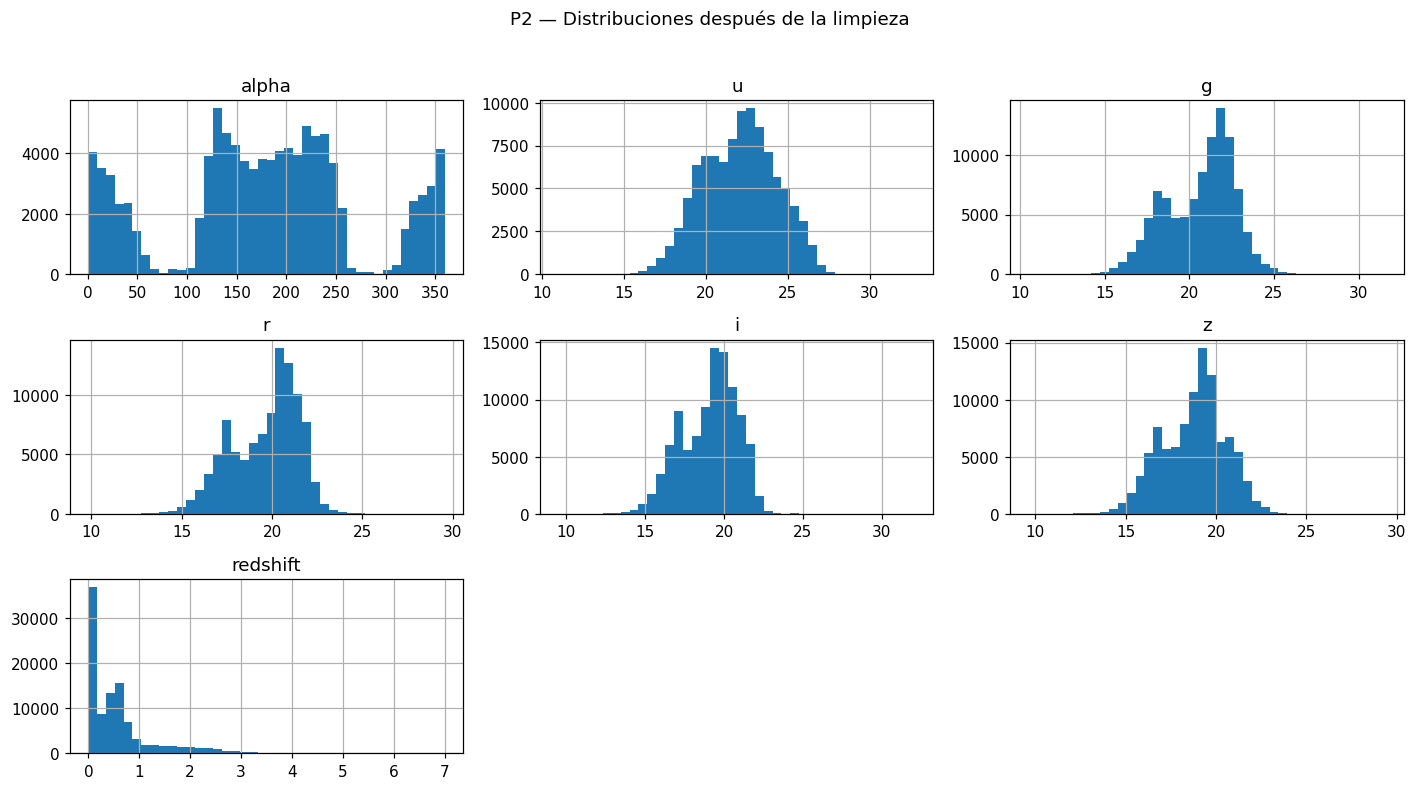

In [ ]:
p2_num = p2_raw[p2_features].apply(pd.to_numeric, errors='coerce')
p2_bad_null = p2_num.isna().any(axis=1) | p2_raw['class'].isna()
p2_bad_finite = ~np.isfinite(p2_num.to_numpy()).all(axis=1)
p2_bad_sentinel = p2_num.eq(-9999).any(axis=1)
p2_bad = p2_bad_null | p2_bad_finite | p2_bad_sentinel
p2_limpieza = pd.DataFrame({
    'control': ['Nulos', 'No finitos (incluye NaN)', 'Centinela -9999',
                'Total excluido (unión)', 'Conservadas'],
    'filas': [p2_bad_null.sum(), p2_bad_finite.sum(), p2_bad_sentinel.sum(),
              p2_bad.sum(), (~p2_bad).sum()],
})
display(p2_limpieza)
display(p2_raw.loc[p2_bad, ['spec_obj_ID', 'class'] + p2_features])
p2_clean = p2_raw.loc[~p2_bad].copy()
p2_clean[p2_features] = p2_num.loc[~p2_bad]
p2_X = p2_clean[p2_features].to_numpy(dtype=float)
p2_y = p2_clean['class'].map(dict(zip(p2_clases, p2_codigos))).to_numpy(dtype=int)
p2_ids = p2_clean.index.to_numpy()
assert len(p2_clean) >= 15000 and len(p2_features) >= 7
assert np.isfinite(p2_X).all() and set(p2_y) == set(p2_codigos)
assert 'class' not in p2_features
assert p2_clean['spec_obj_ID'].is_unique
assert not p2_clean.duplicated(p2_features).any()
display(p2_clean[p2_features].describe().round(4))
display(Markdown(f'Se conservan **{len(p2_clean):,}** filas y se excluyen '
                 f'**{int(p2_bad.sum())}**. Las clases de las filas excluidas son: '
                 f"**{p2_raw.loc[p2_bad, 'class'].value_counts().to_dict()}**."))
p2_clean[p2_features].hist(bins=40, figsize=(13, 7))
plt.suptitle('P2 — Distribuciones después de la limpieza', y=1.02)
plt.tight_layout()
plt.show()

## 2.2 División 80/20 y escenarios de etiquetas

Cada semilla genera un split estratificado 80/20. Dentro del 80%, se seleccionan
aleatoriamente y de forma estratificada las etiquetas conocidas del escenario.
La estratificación usa etiquetas reales **solo para simular el diseño experimental**;
después se separan las etiquetas ocultas de las entradas de entrenamiento.
Los seis enfoques comparten las mismas particiones y folds dentro de cada caso.
El 10% y 30% son presupuestos independientes, no subconjuntos necesariamente anidados.
Los porcentajes están sujetos al redondeo entero de `train_test_split`.

`p2_entradas` contiene características y únicamente las etiquetas conocidas.
`p2_reserva` guarda testing y la verdad oculta para la evaluación final y auditoría.
El ajuste y selección reciben solamente `p2_entradas`.

In [ ]:
def p2_preparar_escenarios(X, y, ids):
    entradas, reserva, resumen = {}, {}, []
    for semilla in p2_semillas:
        tr, te = train_test_split(np.arange(len(y)), test_size=0.20,
                                 stratify=y, random_state=semilla)
        assert set(tr).isdisjoint(te) and len(tr) + len(te) == len(y)
        for escenario, fraccion in p2_escenarios.items():
            conocidos, ocultos = train_test_split(
                tr, train_size=fraccion, stratify=y[tr], random_state=semilla)
            clave = (semilla, escenario)
            entradas[clave] = {
                'X_l': X[conocidos].copy(), 'y_l': y[conocidos].copy(),
                'X_u': X[ocultos].copy(), 'ids_l': ids[conocidos].copy(),
                'ids_u': ids[ocultos].copy(),
            }
            reserva[clave] = {'X_test': X[te].copy(), 'y_test': y[te].copy(),
                              'ids_test': ids[te].copy(), 'y_ocultas': y[ocultos].copy()}
            assert set(conocidos).isdisjoint(ocultos)
            assert set(conocidos) | set(ocultos) == set(tr)
            assert set(y[conocidos]) == set(p2_codigos)
            resumen.append({
                'semilla': semilla, 'escenario': escenario, 'n_train': len(tr),
                'n_test': len(te), 'n_reales': len(conocidos), 'n_ocultas': len(ocultos),
                'fraccion_real': len(conocidos) / len(tr),
                **{f'proporcion_{clase}': np.mean(y[conocidos] == j)
                   for j, clase in enumerate(p2_clases)},
            })
    return entradas, reserva, pd.DataFrame(resumen)

p2_entradas, p2_reserva, p2_particiones = p2_preparar_escenarios(p2_X, p2_y, p2_ids)
display(p2_particiones.round(5))

,semilla,escenario,n_train,n_test,n_reales,n_ocultas,fraccion_real,proporcion_GALAXY,proporcion_QSO,proporcion_STAR
0,42,A_10,79999,20000,7999,72000,0.09999,0.59445,0.18965,0.21590
1,42,B_30,79999,20000,23999,56000,0.29999,0.59444,0.18963,0.21593
2,25,A_10,79999,20000,7999,72000,0.09999,0.59445,0.18965,0.21590
3,25,B_30,79999,20000,23999,56000,0.29999,0.59444,0.18963,0.21593
4,666,A_10,79999,20000,7999,72000,0.09999,0.59445,0.18965,0.21590
5,666,B_30,79999,20000,23999,56000,0.29999,0.59444,0.18963,0.21593


## 2.A — Baselines supervisados y criterio de validación

Cada modelo recibe un `StandardScaler` propio y se ajusta solo con sus muestras
de entrenamiento. Para cada enfoque se exploran **C = 0.01, 1 y 100**:
un C menor incrementa la regularización; uno mayor permite penalizar más los errores
de ajuste. Se mantiene `class_weight=None` para no añadir otra variable experimental.

### 2.A.1 Regresión Logística multinomial

Se utiliza `LogisticRegression(solver='lbfgs', penalty='l2', max_iter=3000)`.
Para tres clases estima probabilidades softmax y minimiza entropía cruzada
multiclase con penalización L2. Su término de datos es
\(-\sum_i \log P(y_i\mid x_i)\); C controla inversamente la fuerza de regularización.

### 2.A.2 SVM lineal

Se utiliza `LinearSVC(loss='squared_hinge', penalty='l2', dual=False,
max_iter=10000)`, con estrategia uno contra el resto. Para cada problema binario,
la pérdida por muestra es \(\max(0,1-y_i f(x_i))^2\), además de la penalización L2.
No estima probabilidades; no se fuerza un ROC-AUC a partir de etiquetas predichas.

### Validación común

Se usa `StratifiedKFold(5, shuffle=True, random_state=semilla)` sobre las etiquetas
reales conocidas. Se registra F1 macro, accuracy, precisión macro y recall macro.
Se elige el mayor F1 macro promedio; en igualdad exacta se prefiere menor C y
luego el orden declarado del clustering. Los scores de CV son para selección;
la estimación final de generalización proviene del testing reservado.

In [ ]:
def p2_metricas(y_real, pred):
    return {
        'f1_macro': f1_score(y_real, pred, labels=p2_codigos, average='macro', zero_division=0),
        'accuracy': accuracy_score(y_real, pred),
        'precision_macro': precision_score(y_real, pred, labels=p2_codigos,
                                           average='macro', zero_division=0),
        'recall_macro': recall_score(y_real, pred, labels=p2_codigos,
                                     average='macro', zero_division=0),
    }

def p2_modelo(nombre, C, semilla):
    if nombre == 'RL':
        estimador = LogisticRegression(C=C, solver='lbfgs', penalty='l2',
                                       class_weight=None, max_iter=3000)
    elif nombre == 'SVM':
        estimador = P2LinearSVC(C=C, loss='squared_hinge', penalty='l2', dual=False,
                               class_weight=None, max_iter=10000, random_state=semilla)
    else:
        raise ValueError(nombre)
    return make_pipeline(StandardScaler(), estimador)

def p2_ajustar(modelo, X, y):
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter('always', ConvergenceWarning)
        modelo.fit(X, y)
    convergencia = [str(a.message) for a in avisos
                    if issubclass(a.category, ConvergenceWarning)]
    otros = [a for a in avisos if not issubclass(a.category, ConvergenceWarning)]
    for aviso in otros:
        warnings.warn(str(aviso.message), aviso.category)
    if convergencia:
        raise RuntimeError('P2: resolver convergencia antes de continuar: ' + '; '.join(convergencia))
    return modelo

## 2.B — Clustering para pseudoetiquetado

### 2.B.1 K-Means

Se investigan **k=6** y **k=12**, ambos con `n_init=10`. Más de tres clústeres
permite representar subgrupos de una misma clase; un clúster no equivale a una clase.
Su objetivo es minimizar la suma de distancias euclidianas cuadradas al centroide.

### 2.B.2 DBSCAN

Se fija `min_samples=10` y se comparan dos `eps`: percentiles 50 y 75 de la distancia
al décimo vecino distinto de la propia muestra. Se consultan hasta 10.000 puntos
reproducibles contra todo el conjunto disponible para ese ajuste.
El percentil mayor expande los vecindarios, pudiendo aumentar cobertura o mezclar clases.
DBSCAN utiliza conectividad por densidad y no minimiza una pérdida de centroides.
Las distancias se almacenan en un grafo disperso construido por bloques.

### 2.B.3 Correspondencia entre clústeres y clases

El escalador del clustering se ajusta sobre conocidas de entrenamiento + desconocidas,
excluyendo por completo la validación del fold. Un clúster se admite si tiene al
menos **cinco etiquetas reales**, mayoría única y **pureza ≥0.80**. La pureza es
la proporción de etiquetas conocidas de su clase mayoritaria; **no garantiza** la
exactitud de las pseudoetiquetas.

En K-Means se ordenan los candidatos por pureza descendente y distancia al centroide
ascendente. En DBSCAN solo se consideran puntos núcleo de clústeres válidos:
se excluye ruido (`-1`) y puntos frontera; se requiere además un núcleo con etiqueta
real de la clase mayoritaria para medir cercanía. La distancia se mide al más próximo
de esos núcleos. Los empates se resuelven por el índice original de la observación.

La meta es `ceil(0.60 × N)` etiquetas totales, incluyendo las reales. En CV, N es
el total disponible después de retirar el fold de validación. Nunca se reemplazan
etiquetas reales ni se relajan las reglas para forzar cobertura. Si no hay candidatos
suficientes se registra el déficit. Ambas clases de etiquetas reciben igual peso.

In [ ]:
def p2_grafo_radio(Z, eps, bloque=2048):
    vecinos = P2NearestNeighbors(radius=eps, algorithm='kd_tree', n_jobs=1).fit(Z)
    bloques = [vecinos.radius_neighbors_graph(
        Z[inicio:inicio + bloque], mode='distance', sort_results=True
    ) for inicio in range(0, len(Z), bloque)]
    grafo = p2_sparse.vstack(bloques, format='csr')
    # El radio incluye a cada punto: conservar las entradas cero de la diagonal.
    assert grafo.shape == (len(Z), len(Z))
    return grafo

def p2_pseudoetiquetar(X_l, y_l, X_u, ids_u, config, semilla):
    """No recibe etiquetas ocultas, etiquetas de validación ni testing.

    Retorna posiciones relativas a X_u, etiquetas estimadas y diagnósticos.
    """
    inicio = p2_time.perf_counter()
    n_l, n_u = len(y_l), len(X_u)
    assert len(X_l) == n_l and len(ids_u) == n_u
    Z = StandardScaler().fit_transform(np.vstack([X_l, X_u]))
    es_db = config['metodo'] == 'dbscan'
    eps, aristas = np.nan, 0
    if not es_db:
        cluster = P2KMeans(n_clusters=config['k'], n_init=10, random_state=semilla)
        grupos = cluster.fit_predict(Z)
        nucleos = np.ones(len(Z), dtype=bool)
    else:
        rng = np.random.default_rng(semilla)
        consulta = rng.choice(len(Z), size=min(10000, len(Z)), replace=False)
        vecinos = P2NearestNeighbors(n_neighbors=11, algorithm='kd_tree', n_jobs=1).fit(Z)
        distancias = vecinos.kneighbors(Z[consulta], return_distance=True)[0][:, -1]
        eps = max(float(np.quantile(distancias, config['q'])), np.finfo(float).eps)
        grafo = p2_grafo_radio(Z, eps)
        aristas = grafo.nnz
        cluster = P2DBSCAN(eps=eps, min_samples=config['min_samples'],
                          metric='precomputed', n_jobs=1).fit(grafo)
        grupos = cluster.labels_
        nucleos = np.zeros(len(Z), dtype=bool)
        nucleos[cluster.core_sample_indices_] = True
        del grafo
    candidatos, etiquetas, purezas, distancias_candidatos = [], [], [], []
    detalle = []
    for grupo in np.unique(grupos):
        if grupo == -1:
            continue
        conocidos = np.flatnonzero(grupos[:n_l] == grupo)
        conteos = np.bincount(y_l[conocidos], minlength=len(p2_clases))
        soporte = len(conocidos)
        clase = int(np.argmax(conteos))
        pureza = float(conteos[clase] / soporte) if soporte else 0.0
        valido = soporte >= 5 and np.sum(conteos == conteos.max()) == 1 and pureza >= 0.80
        pos_u = np.flatnonzero(grupos[n_l:] == grupo)
        if es_db:
            pos_u = pos_u[nucleos[n_l:][pos_u]]
            anclas = conocidos[nucleos[conocidos] & (y_l[conocidos] == clase)]
            valido = valido and len(anclas) > 0
        detalle.append({'cluster': int(grupo), 'n_total': int(np.sum(grupos == grupo)),
                        'n_reales': soporte, 'clase': p2_clases[clase], 'pureza': pureza,
                        'valido': bool(valido), 'n_candidatos': len(pos_u) if valido else 0})
        if not valido or not len(pos_u):
            continue
        if es_db:
            cercanos = P2NearestNeighbors(n_neighbors=1, algorithm='kd_tree').fit(Z[anclas])
            distancia = cercanos.kneighbors(Z[n_l + pos_u])[0][:, 0]
        else:
            distancia = np.linalg.norm(Z[n_l + pos_u] - cluster.cluster_centers_[grupo], axis=1)
        candidatos.extend(pos_u.tolist())
        etiquetas.extend([clase] * len(pos_u))
        purezas.extend([pureza] * len(pos_u))
        distancias_candidatos.extend(distancia.tolist())
    candidatos = np.asarray(candidatos, dtype=int)
    etiquetas = np.asarray(etiquetas, dtype=int)
    objetivo = int(np.ceil(0.60 * len(Z)))
    presupuesto = max(0, objetivo - n_l)
    orden = np.lexsort((ids_u[candidatos], np.asarray(distancias_candidatos),
                        -np.asarray(purezas))) if len(candidatos) else np.array([], dtype=int)
    tomar = orden[:presupuesto]
    seleccion = candidatos[tomar]
    y_pseudo = etiquetas[tomar]
    n_total = n_l + len(seleccion)
    diag = {
        'cluster_id': config['id'], 'metodo': config['metodo'], 'eps': eps,
        'k': config.get('k', np.nan), 'min_samples': config.get('min_samples', np.nan),
        'n_disponibles': len(Z), 'n_reales': n_l, 'n_pseudo': len(seleccion),
        'n_candidatos': len(candidatos), 'n_objetivo': objetivo,
        'deficit': max(0, objetivo - n_total), 'cobertura': n_total / len(Z),
        'n_clusters': len(detalle), 'n_clusters_validos': sum(d['valido'] for d in detalle),
        'fraccion_ruido': float(np.mean(grupos == -1)), 'aristas': aristas,
        'segundos_cluster': p2_time.perf_counter() - inicio,
    }
    assert len(np.unique(seleccion)) == len(seleccion)
    assert n_total <= max(n_l, objetivo)
    assert set(y_pseudo).issubset(p2_codigos)
    return {'indices_u': seleccion, 'y_pseudo': y_pseudo,
            'diagnostico': diag, 'clusters': pd.DataFrame(detalle)}

## 2.C — Entrenamiento con pseudoetiquetas y registro completo

### 2.C.1 Regresión Logística + K-Means / DBSCAN
### 2.C.2 SVM + K-Means / DBSCAN

En cada fold se generan cuatro conjuntos de pseudoetiquetas (dos configuraciones
por técnica). Cada uno se reutiliza para tres valores de C de cada clasificador.
Los baselines usan las mismas etiquetas reales y folds, sin acceso a las características
desconocidas. Los clasificadores semisupervisados reciben un escalador propio ajustado
solo con las muestras reales y pseudoetiquetadas que efectivamente utilizan.

### 2.C.3 Registro de configuraciones

Cada caso evalúa 6 configuraciones supervisadas y 24 semisupervisadas:
**30 configuraciones × 5 folds × 6 casos = 900 ajustes de CV**.
Se registra la configuración completa, la pérdida, las cuatro métricas, tiempo,
convergencia y cobertura. La selección conjunta de clustering y C usa solamente CV.
Después se reconstruye el pseudoetiquetado con todas las etiquetas reales disponibles
del escenario y se ajustan los seis ganadores. Testing sigue reservado.

In [ ]:
def p2_validar_caso(entrada, semilla, escenario):
    X_l, y_l, X_u = (entrada[k] for k in ['X_l', 'y_l', 'X_u'])
    cv = P2StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla)
    registros, registros_cluster = [], []
    for fold, (tr, va) in enumerate(cv.split(X_l, y_l), start=1):
        assert set(entrada['ids_l'][va]).isdisjoint(entrada['ids_u'])
        assert set(tr).isdisjoint(va)
        aumentos = [('supervisado', None, None)]
        for orden, config in enumerate(p2_cluster_configs):
            pseudo = p2_pseudoetiquetar(X_l[tr], y_l[tr], X_u, entrada['ids_u'], config, semilla)
            registros_cluster.append({'semilla': semilla, 'escenario': escenario,
                                      'fold': fold, **pseudo['diagnostico']})
            aumentos.append((config['metodo'], orden, pseudo))
        for metodo, orden, pseudo in aumentos:
            if pseudo is None:
                Xa, ya = X_l[tr], y_l[tr]
                cid, cobertura, n_pseudo, segundos_cluster = 'ninguno', len(tr)/(len(tr)+len(X_u)), 0, 0.0
            else:
                Xa = np.vstack([X_l[tr], X_u[pseudo['indices_u']]])
                ya = np.concatenate([y_l[tr], pseudo['y_pseudo']])
                d = pseudo['diagnostico']
                cid, cobertura, n_pseudo, segundos_cluster = (
                    d['cluster_id'], d['cobertura'], d['n_pseudo'], d['segundos_cluster'])
            for nombre in ['RL', 'SVM']:
                for C in p2_cs:
                    inicio = p2_time.perf_counter()
                    modelo = p2_ajustar(p2_modelo(nombre, C, semilla), Xa, ya)
                    pred = modelo.predict(X_l[va])
                    registros.append({
                        'semilla': semilla, 'escenario': escenario, 'fold': fold, 'etapa': 'cv',
                        'enfoque': f'{nombre}_{metodo}', 'modelo': nombre, 'C': C,
                        'cluster_id': cid, 'orden_cluster': -1 if orden is None else orden,
                        'perdida': 'entropia_cruzada_multinomial_L2' if nombre == 'RL' else 'squared_hinge_OvR_L2',
                        'convergio': True, 'n_reales': len(tr), 'n_pseudo': n_pseudo,
                        'cobertura': cobertura, 'segundos_ajuste': p2_time.perf_counter()-inicio,
                        'segundos_cluster_compartido': segundos_cluster,
                        **p2_metricas(y_l[va], pred),
                    })
        print(f'P2 CV: semilla={semilla}, {escenario}, fold={fold}/5', flush=True)
    return registros, registros_cluster

def p2_resumir_cv(registros):
    tabla = pd.DataFrame(registros)
    claves = ['semilla', 'escenario', 'enfoque', 'modelo', 'C', 'cluster_id', 'orden_cluster', 'perdida']
    resumen = tabla.groupby(claves, as_index=False).agg(
        f1_macro_media=('f1_macro', 'mean'), f1_macro_std=('f1_macro', 'std'),
        accuracy_media=('accuracy', 'mean'), precision_macro_media=('precision_macro', 'mean'),
        recall_macro_media=('recall_macro', 'mean'), cobertura_media=('cobertura', 'mean'),
        n_pseudo_media=('n_pseudo', 'mean'), segundos_ajuste_total=('segundos_ajuste', 'sum'),
        convergio=('convergio', 'all'), folds=('fold', 'nunique'))
    orden = resumen.sort_values(
        ['semilla', 'escenario', 'enfoque', 'f1_macro_media', 'C', 'orden_cluster'],
        ascending=[True, True, True, False, True, True], kind='stable')
    ganadores = orden.groupby(['semilla', 'escenario', 'enfoque'], sort=False).head(1).copy()
    return tabla, resumen, ganadores

def p2_entrenar_ganadores(entradas, ganadores):
    modelos, pseudo_final, diagnosticos, detalles = {}, {}, [], []
    for (semilla, escenario), entrada in entradas.items():
        filas = ganadores.loc[(ganadores.semilla == semilla) & (ganadores.escenario == escenario)]
        configs_elegidas = set(filas.cluster_id) - {'ninguno'}
        for config in p2_cluster_configs:
            if config['id'] not in configs_elegidas:
                continue
            p = p2_pseudoetiquetar(entrada['X_l'], entrada['y_l'], entrada['X_u'],
                                   entrada['ids_u'], config, semilla)
            pseudo_final[(semilla, escenario, config['id'])] = p
            diagnosticos.append({'semilla': semilla, 'escenario': escenario, **p['diagnostico']})
            detalles.append(p['clusters'].assign(semilla=semilla, escenario=escenario,
                                                 cluster_id=config['id']))
        for fila in filas.itertuples():
            Xa, ya = entrada['X_l'], entrada['y_l']
            if fila.cluster_id != 'ninguno':
                p = pseudo_final[(semilla, escenario, fila.cluster_id)]
                Xa = np.vstack([Xa, entrada['X_u'][p['indices_u']]])
                ya = np.concatenate([ya, p['y_pseudo']])
            inicio = p2_time.perf_counter()
            modelo = p2_ajustar(p2_modelo(fila.modelo, fila.C, semilla), Xa, ya)
            modelos[(semilla, escenario, fila.enfoque)] = {
                'modelo': modelo, 'C': fila.C, 'cluster_id': fila.cluster_id,
                'f1_cv': fila.f1_macro_media, 'n_reales': len(entrada['y_l']),
                'n_pseudo': len(ya)-len(entrada['y_l']), 'n_disponibles': len(entrada['X_l'])+len(entrada['X_u']),
                'segundos_ajuste_final': p2_time.perf_counter()-inicio,
            }
        print(f'P2 ajuste final: semilla={semilla}, {escenario}, seis ganadores', flush=True)
    return modelos, pseudo_final, pd.DataFrame(diagnosticos), pd.concat(detalles, ignore_index=True)

p2_inicio_experimento = p2_time.perf_counter()
p2_registros_cv, p2_registros_cluster_cv = [], []
with p2_threadpool_limits(limits=1):
    for (p2_s, p2_e), p2_entrada in p2_entradas.items():
        p2_r, p2_rc = p2_validar_caso(p2_entrada, p2_s, p2_e)
        p2_registros_cv.extend(p2_r)
        p2_registros_cluster_cv.extend(p2_rc)
    p2_cv_folds, p2_cv_configs, p2_ganadores = p2_resumir_cv(p2_registros_cv)
    p2_modelos_finales, p2_pseudo_final, p2_cluster_final, p2_detalle_clusters = p2_entrenar_ganadores(
        p2_entradas, p2_ganadores)
p2_cluster_cv = pd.DataFrame(p2_registros_cluster_cv)
p2_segundos_experimento = p2_time.perf_counter() - p2_inicio_experimento
assert len(p2_cv_folds) == 900 and len(p2_cv_configs) == 180 and len(p2_ganadores) == 36
assert p2_cv_configs['folds'].eq(5).all()
assert p2_cv_folds['convergio'].all()
print(f'Experimento seleccionado y ajustado en {p2_segundos_experimento/60:.2f} minutos.')
display(p2_ganadores[['semilla', 'escenario', 'enfoque', 'C', 'cluster_id',
                      'f1_macro_media', 'f1_macro_std', 'cobertura_media']].round(5))

P2 CV: semilla=42, A_10, fold=1/5


P2 CV: semilla=42, A_10, fold=2/5


P2 CV: semilla=42, A_10, fold=3/5


P2 CV: semilla=42, A_10, fold=4/5


P2 CV: semilla=42, A_10, fold=5/5


P2 CV: semilla=42, B_30, fold=1/5


... (28 outputs left out)

P2 ajuste final: semilla=666, A_10, seis ganadores


P2 ajuste final: semilla=666, B_30, seis ganadores


Experimento seleccionado y ajustado en 5.66 minutos.


,semilla,escenario,enfoque,C,cluster_id,f1_macro_media,f1_macro_std,cobertura_media
4,25,A_10,RL_dbscan,100.0,db_q50,0.95455,0.00121,0.10643
11,25,A_10,RL_kmeans,100.0,km_6,0.95095,0.00296,0.19427
14,25,A_10,RL_supervisado,100.0,ninguno,0.95163,0.00181,0.08162
20,25,A_10,SVM_dbscan,100.0,db_q75,0.93564,0.00641,0.08383
26,25,A_10,SVM_kmeans,100.0,km_6,0.91934,0.00703,0.19427
29,25,A_10,SVM_supervisado,100.0,ninguno,0.93150,0.00428,0.08162
34,25,B_30,RL_dbscan,100.0,db_q50,0.95375,0.00505,0.27400
41,25,B_30,RL_kmeans,100.0,km_6,0.95326,0.00464,0.34667
44,25,B_30,RL_supervisado,100.0,ninguno,0.95340,0.00576,0.25531
50,25,B_30,SVM_dbscan,100.0,db_q75,0.93461,0.00677,0.26344


In [ ]:
# Todas las configuraciones: las 180 filas permanecen visibles en el resultado.
with pd.option_context('display.max_rows', 200, 'display.max_columns', 20):
    display(p2_cv_configs.round(5))
display(Markdown(
    f'**Registro:** {len(p2_cv_configs)} configuraciones, {len(p2_cv_folds)} ajustes de CV '
    f'y {len(p2_cluster_cv)} ajustes de clustering en CV. Los datos por fold están '
    'en `p2_cv_folds`; los eps, tiempos y coberturas por clustering, en `p2_cluster_cv`. '
    'El tiempo de clustering es compartido por los clasificadores y no debe sumarse '
    'repetidamente por cada valor de C.'
))
display(p2_cluster_cv.groupby(['escenario', 'cluster_id'], as_index=False).agg(
    eps_min=('eps', 'min'), eps_max=('eps', 'max'),
    cobertura_media=('cobertura', 'mean'), deficit_medio=('deficit', 'mean'),
    ruido_medio=('fraccion_ruido', 'mean'), segundos_medios=('segundos_cluster', 'mean')
).round(5))

,semilla,escenario,enfoque,modelo,C,cluster_id,orden_cluster,perdida,f1_macro_media,f1_macro_std,accuracy_media,precision_macro_media,recall_macro_media,cobertura_media,n_pseudo_media,segundos_ajuste_total,convergio,folds
0,25,A_10,RL_dbscan,RL,0.01,db_q50,2,entropia_cruzada_multinomial_L2,0.83972,0.00822,0.86136,0.87035,0.82055,0.10643,1945.0,0.06731,True,5
1,25,A_10,RL_dbscan,RL,0.01,db_q75,3,entropia_cruzada_multinomial_L2,0.85017,0.01301,0.87011,0.88282,0.82722,0.08383,173.0,0.05525,True,5
2,25,A_10,RL_dbscan,RL,1.00,db_q50,2,entropia_cruzada_multinomial_L2,0.94247,0.00445,0.94924,0.94076,0.94569,0.10643,1945.0,0.13877,True,5
3,25,A_10,RL_dbscan,RL,1.00,db_q75,3,entropia_cruzada_multinomial_L2,0.94096,0.00475,0.94824,0.94206,0.94168,0.08383,173.0,0.12787,True,5
4,25,A_10,RL_dbscan,RL,100.00,db_q50,2,entropia_cruzada_multinomial_L2,0.95455,0.00121,0.96062,0.95623,0.95355,0.10643,1945.0,0.19728,True,5
5,25,A_10,RL_dbscan,RL,100.00,db_q75,3,entropia_cruzada_multinomial_L2,0.95105,0.00171,0.95787,0.95510,0.94814,0.08383,173.0,0.16115,True,5
6,25,A_10,RL_kmeans,RL,0.01,km_12,1,entropia_cruzada_multinomial_L2,0.81836,0.01300,0.84523,0.85043,0.80296,0.37069,22662.4,0.20341,True,5
7,25,A_10,RL_kmeans,RL,0.01,km_6,0,entropia_cruzada_multinomial_L2,0.81610,0.01131,0.84111,0.83914,0.80772,0.19427,8831.4,0.11372,True,5
8,25,A_10,RL_kmeans,RL,1.00,km_12,1,entropia_cruzada_multinomial_L2,0.87729,0.00720,0.89111,0.89697,0.86256,0.37069,22662.4,0.42781,True,5
9,25,A_10,RL_kmeans,RL,1.00,km_6,0,entropia_cruzada_multinomial_L2,0.93777,0.00587,0.94474,0.93452,0.94234,0.19427,8831.4,0.27448,True,5


**Registro:** 180 configuraciones, 900 ajustes de CV y 120 ajustes de clustering en CV. Los datos por fold están en `p2_cv_folds`; los eps, tiempos y coberturas por clustering, en `p2_cluster_cv`. El tiempo de clustering es compartido por los clasificadores y no debe sumarse repetidamente por cada valor de C.

,escenario,cluster_id,eps_min,eps_max,cobertura_media,deficit_medio,ruido_medio,segundos_medios
0,A_10,db_q50,0.22681,0.23039,0.10673,38672.06667,0.33981,2.44955
1,A_10,db_q75,0.30653,0.31176,0.08308,40526.53333,0.13659,3.65569
2,A_10,km_12,NaN,NaN,0.36991,18039.20000,0.00000,1.43971
3,A_10,km_6,NaN,NaN,0.19442,31797.26667,0.00000,0.83389
4,B_30,db_q50,0.22767,0.23113,0.27595,24368.93333,0.34270,2.34072
5,B_30,db_q75,0.30855,0.31517,0.25957,25600.26667,0.13691,3.44196
6,B_30,km_12,NaN,NaN,0.49027,8252.06667,0.00000,1.38894
7,B_30,km_6,NaN,NaN,0.34681,19039.86667,0.00000,0.89925


## 2.D — Comparación final de los seis enfoques

Con las configuraciones y modelos ya congelados, se accede a testing una sola vez
por ganador. Se conservan las predicciones para calcular tablas y matrices sin
reentrenar. Las métricas se agregan por enfoque y escenario sobre tres semillas;
la desviación estándar utiliza `ddof=1`. Los splits varían entre semillas: esta
dispersión describe sensibilidad al particionado y no un intervalo de confianza.
Los seis enfoques sí están emparejados dentro de cada semilla.

,semilla,escenario,enfoque,etapa,C,cluster_id,f1_cv,n_reales,n_pseudo,cobertura,segundos_ajuste_final,f1_macro,accuracy,precision_macro,recall_macro
12,25,A_10,RL_dbscan,test,100.0,db_q50,0.95455,7999,1915,0.12393,0.05019,0.95545,0.96130,0.95676,0.95463
0,42,A_10,RL_dbscan,test,100.0,db_q50,0.95515,7999,1829,0.12285,0.04081,0.95616,0.96200,0.95871,0.95440
24,666,A_10,RL_dbscan,test,100.0,db_q50,0.95222,7999,2073,0.12590,0.04087,0.95415,0.96030,0.95652,0.95247
13,25,A_10,RL_kmeans,test,100.0,km_6,0.95095,7999,8851,0.21063,0.08364,0.95443,0.96030,0.95447,0.95483
1,42,A_10,RL_kmeans,test,100.0,km_6,0.95241,7999,8820,0.21024,0.07369,0.95521,0.96105,0.95678,0.95434
25,666,A_10,RL_kmeans,test,100.0,km_6,0.94991,7999,8867,0.21083,0.08054,0.95287,0.95895,0.95297,0.95326
14,25,A_10,RL_supervisado,test,100.0,ninguno,0.95163,7999,0,0.09999,0.04265,0.95456,0.96080,0.95829,0.95166
2,42,A_10,RL_supervisado,test,100.0,ninguno,0.95379,7999,0,0.09999,0.03413,0.95461,0.96080,0.95870,0.95158
26,666,A_10,RL_supervisado,test,100.0,ninguno,0.95085,7999,0,0.09999,0.03613,0.95340,0.95980,0.95705,0.95062
15,25,A_10,SVM_dbscan,test,100.0,db_q75,0.93564,7999,144,0.10179,0.01937,0.93923,0.94565,0.93819,0.94056


,escenario,enfoque,cobertura_media,f1 (media ± std),accuracy (media ± std),precision (media ± std),recall (media ± std)
0,A_10,RL_dbscan,0.124227,0.9553 ± 0.0010,0.9612 ± 0.0009,0.9573 ± 0.0012,0.9538 ± 0.0012
1,A_10,RL_kmeans,0.210565,0.9542 ± 0.0012,0.9601 ± 0.0011,0.9547 ± 0.0019,0.9541 ± 0.0008
2,A_10,RL_supervisado,0.099989,0.9542 ± 0.0007,0.9605 ± 0.0006,0.9580 ± 0.0009,0.9513 ± 0.0006
3,A_10,SVM_dbscan,0.101426,0.9370 ± 0.0047,0.9437 ± 0.0043,0.9369 ± 0.0033,0.9374 ± 0.0060
4,A_10,SVM_kmeans,0.210565,0.9211 ± 0.0036,0.9291 ± 0.0032,0.9245 ± 0.0028,0.9192 ± 0.0043
5,A_10,SVM_supervisado,0.099989,0.9329 ± 0.0035,0.9400 ± 0.0031,0.9370 ± 0.0040,0.9294 ± 0.0032
6,B_30,RL_dbscan,0.319429,0.9556 ± 0.0018,0.9617 ± 0.0015,0.9592 ± 0.0017,0.9529 ± 0.0019
7,B_30,RL_kmeans,0.386063,0.9551 ± 0.0014,0.9612 ± 0.0012,0.9580 ± 0.0014,0.9529 ± 0.0014
8,B_30,RL_supervisado,0.299991,0.9552 ± 0.0015,0.9615 ± 0.0013,0.9594 ± 0.0014,0.9519 ± 0.0016
9,B_30,SVM_dbscan,0.301375,0.9361 ± 0.0026,0.9430 ± 0.0023,0.9390 ± 0.0030,0.9336 ± 0.0022


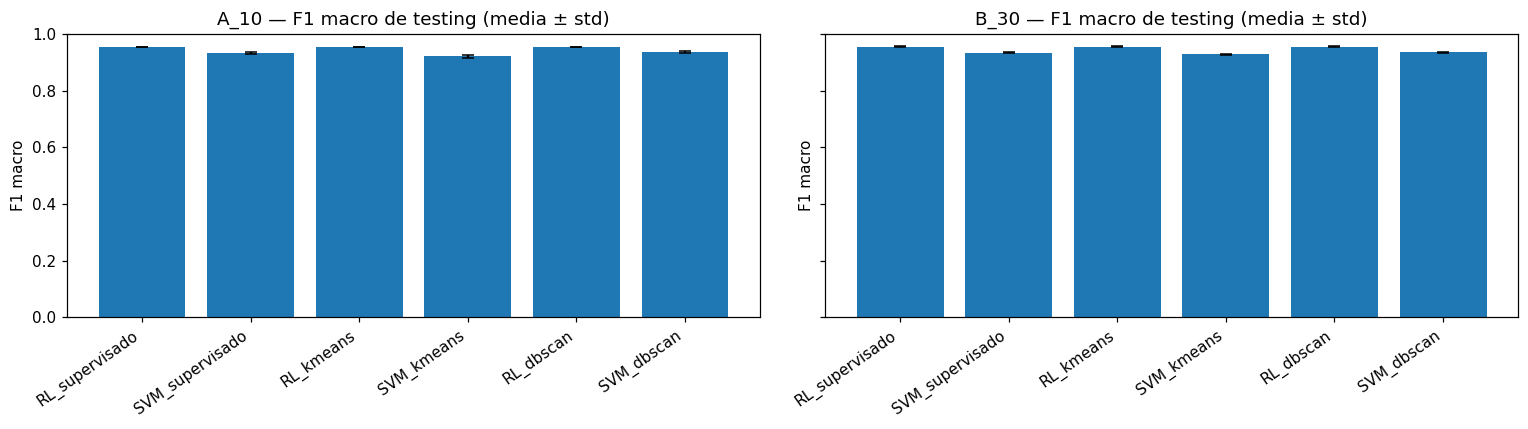

In [ ]:
p2_predicciones, p2_filas_test, p2_matrices = {}, [], {}
for p2_clave, p2_ajuste in p2_modelos_finales.items():
    p2_s, p2_e, p2_enfoque = p2_clave
    p2_holdout = p2_reserva[(p2_s, p2_e)]
    p2_pred = p2_ajuste['modelo'].predict(p2_holdout['X_test'])
    p2_predicciones[p2_clave] = p2_pred.copy()
    p2_matrices[p2_clave] = confusion_matrix(p2_holdout['y_test'], p2_pred, labels=p2_codigos)
    p2_filas_test.append({
        'semilla': p2_s, 'escenario': p2_e, 'enfoque': p2_enfoque, 'etapa': 'test',
        'C': p2_ajuste['C'], 'cluster_id': p2_ajuste['cluster_id'],
        'f1_cv': p2_ajuste['f1_cv'], 'n_reales': p2_ajuste['n_reales'],
        'n_pseudo': p2_ajuste['n_pseudo'],
        'cobertura': (p2_ajuste['n_reales']+p2_ajuste['n_pseudo'])/p2_ajuste['n_disponibles'],
        'segundos_ajuste_final': p2_ajuste['segundos_ajuste_final'],
        **p2_metricas(p2_holdout['y_test'], p2_pred),
    })
p2_test = pd.DataFrame(p2_filas_test).sort_values(['escenario', 'enfoque', 'semilla'])
p2_resumen_test = p2_test.groupby(['escenario', 'enfoque']).agg(
    semillas=('semilla', 'nunique'), f1_media=('f1_macro', 'mean'), f1_std=('f1_macro', 'std'),
    accuracy_media=('accuracy', 'mean'), accuracy_std=('accuracy', 'std'),
    precision_media=('precision_macro', 'mean'), precision_std=('precision_macro', 'std'),
    recall_media=('recall_macro', 'mean'), recall_std=('recall_macro', 'std'),
    cobertura_media=('cobertura', 'mean'), n_pseudo_medio=('n_pseudo', 'mean')).reset_index()
display(p2_test.round(5))
p2_presentacion = p2_resumen_test[['escenario', 'enfoque', 'cobertura_media']].copy()
for p2_nombre in ['f1', 'accuracy', 'precision', 'recall']:
    p2_presentacion[p2_nombre + ' (media ± std)'] = [
        f'{m:.4f} ± {s:.4f}' for m, s in zip(
            p2_resumen_test[p2_nombre+'_media'], p2_resumen_test[p2_nombre+'_std'])]
display(p2_presentacion)

fig, p2_axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for p2_ax, p2_e in zip(p2_axes, p2_escenarios):
    p2_d = p2_resumen_test.loc[p2_resumen_test.escenario == p2_e].set_index('enfoque').loc[p2_enfoques]
    p2_ax.bar(np.arange(6), p2_d.f1_media, yerr=p2_d.f1_std, capsize=4)
    p2_ax.set_xticks(np.arange(6), p2_enfoques, rotation=35, ha='right')
    p2_ax.set_title(f'{p2_e} — F1 macro de testing (media ± std)')
    p2_ax.set_ylim(0, 1)
    p2_ax.set_ylabel('F1 macro')
plt.tight_layout()
plt.show()

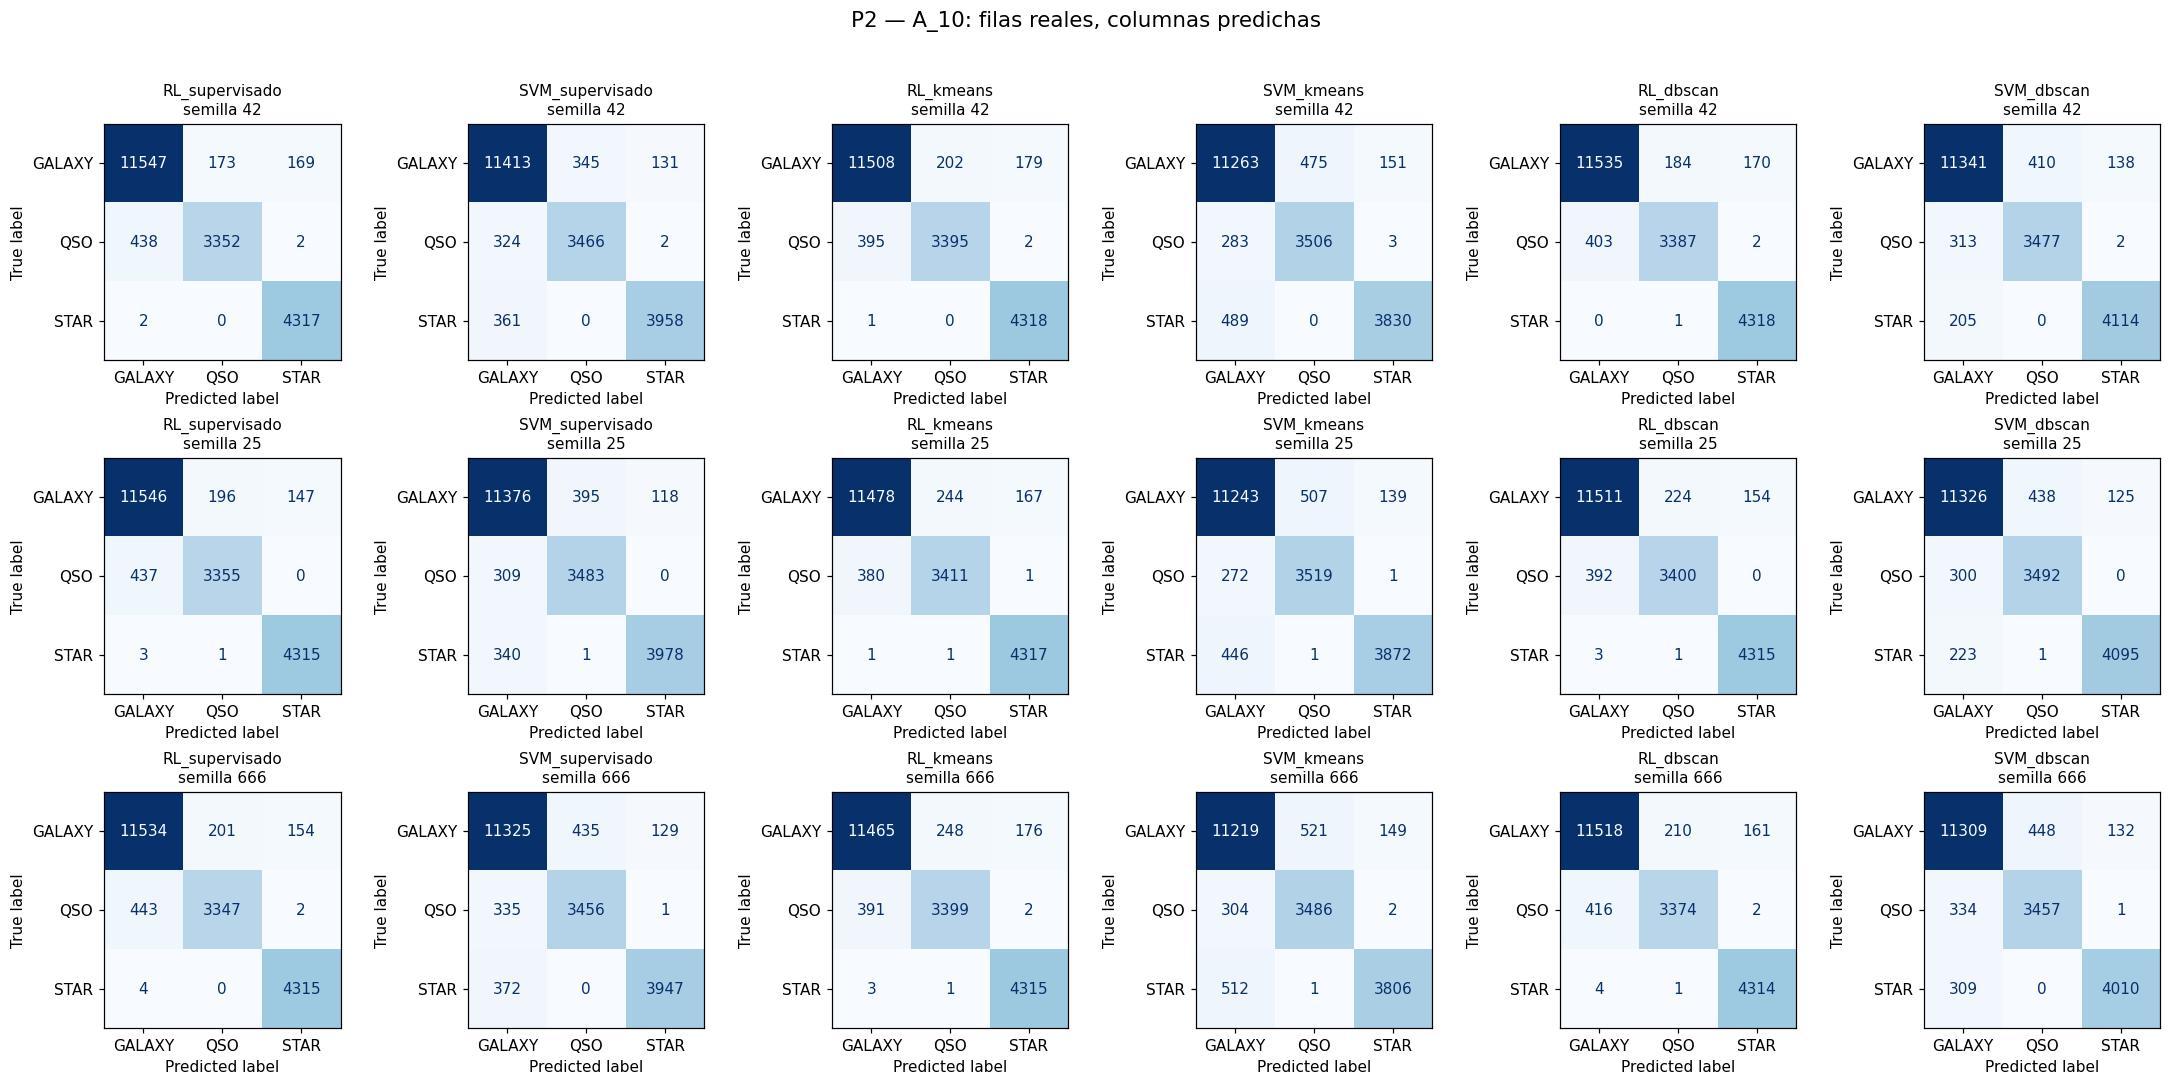

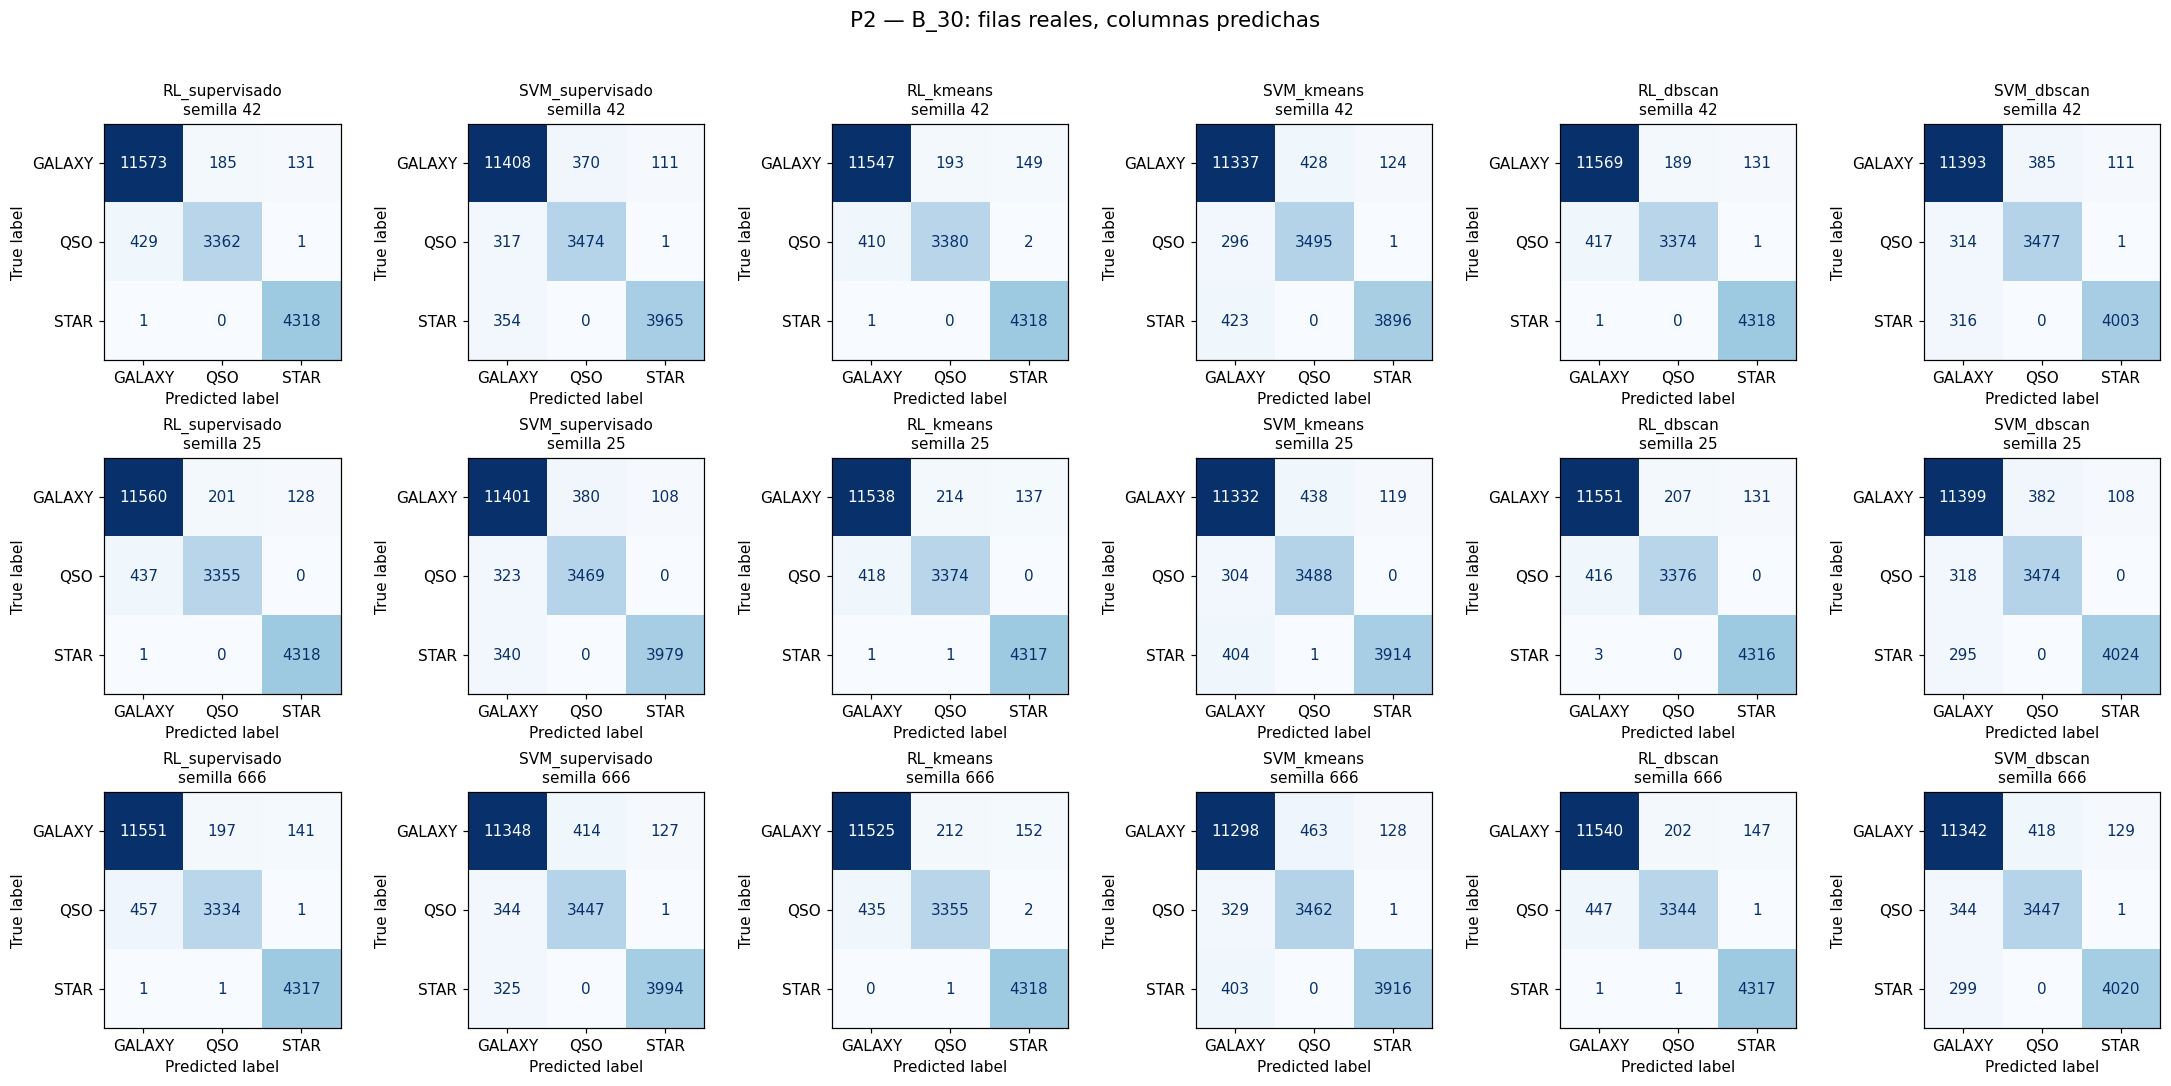

In [ ]:
# Matrices individuales: tres semillas × seis enfoques, separadas por escenario.
for p2_e in p2_escenarios:
    fig, p2_axes = plt.subplots(3, 6, figsize=(20, 10))
    for p2_i, p2_s in enumerate(p2_semillas):
        for p2_j, p2_enfoque in enumerate(p2_enfoques):
            ConfusionMatrixDisplay(p2_matrices[(p2_s, p2_e, p2_enfoque)],
                                   display_labels=p2_clases).plot(
                ax=p2_axes[p2_i, p2_j], colorbar=False, cmap='Blues', values_format='d')
            p2_axes[p2_i, p2_j].set_title(f'{p2_enfoque}\nsemilla {p2_s}', fontsize=10)
    fig.suptitle(f'P2 — {p2_e}: filas reales, columnas predichas', fontsize=14)
    plt.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()

### Auditoría posterior de las pseudoetiquetas

Solo ahora se revelan las etiquetas ocultas de los puntos pseudoetiquetados.
Se informa exactitud global y por clase asignada, número de candidatos, cobertura,
ruido y déficit. Esta auditoría no se usa para elegir hiperparámetros, cambiar
umbrales o repetir la selección. Las pseudoetiquetas de una configuración de
clustering se comparten entre RL y SVM cuando ambos eligieron esa configuración.

In [ ]:
def p2_auditar(pseudo_final, reserva):
    filas, por_clase = [], []
    for (semilla, escenario, cid), pseudo in pseudo_final.items():
        idx, estimadas = pseudo['indices_u'], pseudo['y_pseudo']
        reales = reserva[(semilla, escenario)]['y_ocultas'][idx]
        filas.append({'semilla': semilla, 'escenario': escenario, 'cluster_id': cid,
                      'exactitud_pseudo': accuracy_score(reales, estimadas) if len(idx) else np.nan,
                      **{k: v for k, v in pseudo['diagnostico'].items()
                         if k not in ['cluster_id', 'metodo']}})
        for j, clase in enumerate(p2_clases):
            mask = estimadas == j
            por_clase.append({'semilla': semilla, 'escenario': escenario, 'cluster_id': cid,
                              'clase_asignada': clase, 'n_pseudo': int(mask.sum()),
                              'exactitud': float(np.mean(reales[mask] == j)) if mask.any() else np.nan})
    return pd.DataFrame(filas), pd.DataFrame(por_clase)

p2_auditoria, p2_auditoria_clase = p2_auditar(p2_pseudo_final, p2_reserva)
display(p2_auditoria.round(5))
display(p2_auditoria_clase.round(5))
display(p2_detalle_clusters.round(5))

,semilla,escenario,cluster_id,exactitud_pseudo,eps,k,min_samples,n_disponibles,n_reales,n_pseudo,n_candidatos,n_objetivo,deficit,cobertura,n_clusters,n_clusters_validos,fraccion_ruido,aristas,segundos_cluster
0,42,A_10,km_6,0.99240,NaN,6.0,NaN,79999,7999,8820,8820,48000,31181,0.21024,6,1,0.00000,0,1.11652
1,42,A_10,db_q50,0.99289,0.22693,NaN,10.0,79999,7999,1829,1829,48000,38172,0.12285,108,6,0.34242,2265739,2.51662
2,42,A_10,db_q75,0.98726,0.30938,NaN,10.0,79999,7999,157,157,48000,39844,0.10195,29,3,0.13306,6744157,3.71390
3,42,B_30,km_6,0.99330,NaN,6.0,NaN,79999,23999,6867,6867,48000,17134,0.38583,6,1,0.00000,0,0.93405
4,42,B_30,db_q50,0.99458,0.22600,NaN,10.0,79999,23999,1476,1476,48000,22525,0.31844,109,37,0.34613,2232651,2.43409
5,42,B_30,db_q75,0.98571,0.30795,NaN,10.0,79999,23999,140,140,48000,23861,0.30174,31,8,0.13538,6636771,3.70280
6,25,A_10,km_6,0.99232,NaN,6.0,NaN,79999,7999,8851,8851,48000,31150,0.21063,6,1,0.00000,0,0.77569
7,25,A_10,db_q50,0.99426,0.22742,NaN,10.0,79999,7999,1915,1915,48000,38086,0.12393,105,14,0.34173,2274611,2.43553
8,25,A_10,db_q75,0.96528,0.30986,NaN,10.0,79999,7999,144,144,48000,39857,0.10179,29,4,0.13368,6756671,3.69347
9,25,B_30,km_6,0.99215,NaN,6.0,NaN,79999,23999,6877,6877,48000,17124,0.38595,6,1,0.00000,0,0.89072


,semilla,escenario,cluster_id,clase_asignada,n_pseudo,exactitud
0,42,A_10,km_6,GALAXY,0,NaN
1,42,A_10,km_6,QSO,8820,0.99240
2,42,A_10,km_6,STAR,0,NaN
3,42,A_10,db_q50,GALAXY,181,0.97238
4,42,A_10,db_q50,QSO,1648,0.99515
5,42,A_10,db_q50,STAR,0,NaN
6,42,A_10,db_q75,GALAXY,0,NaN
7,42,A_10,db_q75,QSO,0,NaN
8,42,A_10,db_q75,STAR,157,0.98726
9,42,B_30,km_6,GALAXY,0,NaN


,cluster,n_total,n_reales,clase,pureza,valido,n_candidatos,semilla,escenario,cluster_id
0,0,9805,985,QSO,0.99188,True,8820,42,A_10,km_6
1,1,16308,1661,GALAXY,0.61589,False,0,42,A_10,km_6
2,2,17172,1684,GALAXY,0.75891,False,0,42,A_10,km_6
3,3,13224,1310,GALAXY,0.70382,False,0,42,A_10,km_6
4,4,8112,792,GALAXY,0.56566,False,0,42,A_10,km_6
...,...,...,...,...,...,...,...,...,...,...
792,19,4,1,GALAXY,1.00000,False,0,666,B_30,db_q75
793,20,10,3,STAR,1.00000,False,0,666,B_30,db_q75
794,21,8,2,STAR,1.00000,False,0,666,B_30,db_q75
795,22,8,3,STAR,1.00000,False,0,666,B_30,db_q75


## 2.E — Análisis y conclusiones

Los siguientes textos se generan con las tablas calculadas. Se distingue desempeño
predictivo de pureza interna y de cobertura: alcanzar 60% no garantiza mejorar F1.
No se presume que el semisupervisado mejore al supervisado.

In [ ]:
p2_parrafos = []
for p2_e in p2_escenarios:
    p2_d = p2_resumen_test.loc[p2_resumen_test.escenario == p2_e].set_index('enfoque')
    p2_best = p2_d.f1_media.idxmax()
    p2_parrafos.append(
        f"**{p2_e}.** El mayor F1 macro medio observado en testing corresponde a "
        f"**{p2_best}**: **{p2_d.loc[p2_best, 'f1_media']:.4f} ± "
        f"{p2_d.loc[p2_best, 'f1_std']:.4f}**. Esta comparación describe los "
        'seis ganadores elegidos previamente por CV; no inicia una nueva selección.')
    for p2_nombre in ['RL', 'SVM']:
        p2_base = p2_test.loc[(p2_test.escenario == p2_e) &
                              (p2_test.enfoque == f'{p2_nombre}_supervisado')].set_index('semilla')
        for p2_metodo in ['kmeans', 'dbscan']:
            p2_semi = p2_test.loc[(p2_test.escenario == p2_e) &
                                  (p2_test.enfoque == f'{p2_nombre}_{p2_metodo}')].set_index('semilla')
            p2_delta = p2_semi.f1_macro - p2_base.f1_macro
            p2_parrafos.append(
                f"{p2_nombre}+{p2_metodo}: diferencia emparejada de F1 frente al baseline "
                f"**{p2_delta.mean():+.4f} ± {p2_delta.std(ddof=1):.4f}**; "
                f"mejora en **{int((p2_delta > 0).sum())}/3** semillas. "
                f"Cobertura media: **{p2_semi.cobertura.mean():.2%}**.")

p2_c_efecto = p2_cv_configs.groupby(['escenario', 'enfoque', 'C'], as_index=False).agg(
    f1_cv_medio=('f1_macro_media', 'mean'), f1_cv_std=('f1_macro_media', 'std'))
display(p2_c_efecto.round(5))
display(p2_ganadores.groupby(['escenario', 'enfoque', 'C', 'cluster_id']).size().rename('selecciones').to_frame())
for (p2_e, p2_enfoque), p2_d in p2_c_efecto.groupby(['escenario', 'enfoque']):
    p2_r = p2_d.loc[p2_d.f1_cv_medio.idxmax()]
    p2_parrafos.append(
        f"**Hiperparámetros, {p2_e}/{p2_enfoque}:** el mayor F1 de CV agregado "
        f"por C es **{p2_r.f1_cv_medio:.4f}** con **C={p2_r.C:g}**; "
        f"la amplitud entre valores de C es **{p2_d.f1_cv_medio.max()-p2_d.f1_cv_medio.min():.4f}**. "
        'En los enfoques semisupervisados este resumen promedia también las dos '
        'configuraciones de clustering; la elección efectiva es conjunta y por semilla.')

for p2_enfoque in p2_enfoques:
    p2_p = p2_test.loc[p2_test.enfoque == p2_enfoque].pivot(index='semilla', columns='escenario', values='f1_macro')
    p2_delta = p2_p['B_30'] - p2_p['A_10']
    p2_parrafos.append(
        f"**Etiquetas reales, {p2_enfoque}:** al pasar de 10% a 30%, "
        f"el cambio medio de F1 es **{p2_delta.mean():+.4f} ± {p2_delta.std(ddof=1):.4f}**. "
        'La comparación comparte el testing de cada semilla; los subconjuntos conocidos '
        'de los dos escenarios no son necesariamente anidados.')

for (p2_e, p2_cid), p2_d in p2_auditoria.groupby(['escenario', 'cluster_id']):
    p2_parrafos.append(
        f"**Pseudoetiquetas, {p2_e}/{p2_cid}:** exactitud auditada media "
        f"**{p2_d.exactitud_pseudo.mean():.2%}**, cobertura **{p2_d.cobertura.mean():.2%}**, "
        f"déficit medio **{p2_d.deficit.mean():,.0f}** muestras y ruido medio "
        f"**{p2_d.fraccion_ruido.mean():.2%}**. "
        + ('El déficit refleja candidatos insuficientes bajo las reglas de pureza, soporte '
           'y, para DBSCAN, pertenencia al núcleo y disponibilidad de anclas.'
           if p2_d.deficit.gt(0).any() else 'Se alcanzó la meta en todos los ajustes registrados de esta configuración.')
    )

display(Markdown('\n\n'.join(p2_parrafos)))
display(Markdown(
    '**Interpretación y límites.** Las etiquetas adicionales solo aportan si su señal '
    'compensa sus errores: clústeres geométricos pueden mezclar clases o fragmentar una '
    'misma clase. Un punto núcleo de DBSCAN indica densidad, no certeza de clase. '
    'La pureza se estima con las etiquetas conocidas y puede ser optimista cuando '
    'el soporte es pequeño; por eso se exige un mínimo de cinco. El presupuesto '
    'del 60% es una meta de cobertura, no una garantía de calidad. '
    'Ambos clasificadores tienen fronteras lineales (RL multinomial y SVM OvR): '
    'las pseudoetiquetas no incorporan por sí mismas un kernel no lineal. '
    'Las tres semillas muestran sensibilidad al muestreo, pero no bastan para '
    'afirmar significancia estadística. Las conclusiones se limitan a este dataset, '
    'las siete variables, los rangos explorados y el supuesto de disponer de redshift. '
    'La auditoría de verdad oculta explica resultados después de congelar la selección '
    'y no se utiliza para reajustar el experimento.'
))

,escenario,enfoque,C,f1_cv_medio,f1_cv_std
0,A_10,RL_dbscan,0.01,0.84043,0.00494
1,A_10,RL_dbscan,1.00,0.94304,0.00207
2,A_10,RL_dbscan,100.00,0.95288,0.00180
3,A_10,RL_kmeans,0.01,0.81553,0.00157
4,A_10,RL_kmeans,1.00,0.90863,0.03291
5,A_10,RL_kmeans,100.00,0.93065,0.02250
6,A_10,RL_supervisado,0.01,0.83572,0.00420
7,A_10,RL_supervisado,1.00,0.94254,0.00237
8,A_10,RL_supervisado,100.00,0.95209,0.00152
9,A_10,SVM_dbscan,0.01,0.84063,0.00453


selecciones
escenario enfoque         C     cluster_id             
A_10      RL_dbscan       100.0 db_q50                3
          RL_kmeans       100.0 km_6                  3
          RL_supervisado  100.0 ninguno               3
          SVM_dbscan      100.0 db_q75                3
          SVM_kmeans      100.0 km_6                  3
          SVM_supervisado 100.0 ninguno               3
B_30      RL_dbscan       100.0 db_q50                3
          RL_kmeans       100.0 km_6                  3
          RL_supervisado  100.0 ninguno               3
          SVM_dbscan      100.0 db_q75                3
          SVM_kmeans      100.0 km_6                  3
          SVM_supervisado 100.0 ninguno               3

**A_10.** El mayor F1 macro medio observado en testing corresponde a **RL_dbscan**: **0.9553 ± 0.0010**. Esta comparación describe los seis ganadores elegidos previamente por CV; no inicia una nueva selección.

RL+kmeans: diferencia emparejada de F1 frente al baseline **-0.0000 ± 0.0006**; mejora en **1/3** semillas. Cobertura media: **21.06%**.

RL+dbscan: diferencia emparejada de F1 frente al baseline **+0.0011 ± 0.0004**; mejora en **3/3** semillas. Cobertura media: **12.42%**.

SVM+kmeans: diferencia emparejada de F1 frente al baseline **-0.0118 ± 0.0010**; mejora en **0/3** semillas. Cobertura media: **21.06%**.

SVM+dbscan: diferencia emparejada de F1 frente al baseline **+0.0041 ± 0.0013**; mejora en **3/3** semillas. Cobertura media: **10.14%**.

**B_30.** El mayor F1 macro medio observado en testing corresponde a **RL_dbscan**: **0.9556 ± 0.0018**. Esta comparación describe los seis ganadores elegidos previamente por CV; no inicia una nueva selección.

RL+kmeans: diferencia emparejada de F1 frente al baseline **-0.0001 ± 0.0001**; mejora en **0/3** semillas. Cobertura media: **38.61%**.

RL+dbscan: diferencia emparejada de F1 frente al baseline **+0.0004 ± 0.0004**; mejora en **3/3** semillas. Cobertura media: **31.94%**.

SVM+kmeans: diferencia emparejada de F1 frente al baseline **-0.0062 ± 0.0001**; mejora en **0/3** semillas. Cobertura media: **38.61%**.

SVM+dbscan: diferencia emparejada de F1 frente al baseline **+0.0017 ± 0.0008**; mejora en **3/3** semillas. Cobertura media: **30.14%**.

**Hiperparámetros, A_10/RL_dbscan:** el mayor F1 de CV agregado por C es **0.9529** con **C=100**; la amplitud entre valores de C es **0.1124**. En los enfoques semisupervisados este resumen promedia también las dos configuraciones de clustering; la elección efectiva es conjunta y por semilla.

**Hiperparámetros, A_10/RL_kmeans:** el mayor F1 de CV agregado por C es **0.9306** con **C=100**; la amplitud entre valores de C es **0.1151**. En los enfoques semisupervisados este resumen promedia también las dos configuraciones de clustering; la elección efectiva es conjunta y por semilla.

**Hiperparámetros, A_10/RL_supervisado:** el mayor F1 de CV agregado por C es **0.9521** con **C=100**; la amplitud entre valores de C es **0.1164**. En los enfoques semisupervisados este resumen promedia también las dos configuraciones de clustering; la elección efectiva es conjunta y por semilla.

**Hiperparámetros, A_10/SVM_dbscan:** el mayor F1 de CV agregado por C es **0.9302** con **C=100**; la amplitud entre valores de C es **0.0896**. En los enfoques semisupervisados este resumen promedia también las dos configuraciones de clustering; la elección efectiva es conjunta y por semilla.

**Hiperparámetros, A_10/SVM_kmeans:** el mayor F1 de CV agregado por C es **0.9015** con **C=100**; la amplitud entre valores de C es **0.0857**. En los enfoques semisupervisados este resumen promedia también las dos configuraciones de clustering; la elección efectiva es conjunta y por semilla.

**Hiperparámetros, A_10/SVM_supervisado:** el mayor F1 de CV agregado por C es **0.9318** con **C=100**; la amplitud entre valores de C es **0.0916**. En los enfoques semisupervisados este resumen promedia también las dos configuraciones de clustering; la elección efectiva es conjunta y por semilla.

**Hiperparámetros, B_30/RL_dbscan:** el mayor F1 de CV agregado por C es **0.9532** con **C=100**; la amplitud entre valores de C es **0.0760**. En los enfoques semisupervisados este resumen promedia también las dos configuraciones de clustering; la elección efectiva es conjunta y por semilla.

**Hiperparámetros, B_30/RL_kmeans:** el mayor F1 de CV agregado por C es **0.9450** con **C=100**; la amplitud entre valores de C es **0.0977**. En los enfoques semisupervisados este resumen promedia también las dos configuraciones de clustering; la elección efectiva es conjunta y por semilla.

**Hiperparámetros, B_30/RL_supervisado:** el mayor F1 de CV agregado por C es **0.9532** con **C=100**; la amplitud entre valores de C es **0.0760**. En los enfoques semisupervisados este resumen promedia también las dos configuraciones de clustering; la elección efectiva es conjunta y por semilla.

**Hiperparámetros, B_30/SVM_dbscan:** el mayor F1 de CV agregado por C es **0.9334** con **C=100**; la amplitud entre valores de C es **0.0694**. En los enfoques semisupervisados este resumen promedia también las dos configuraciones de clustering; la elección efectiva es conjunta y por semilla.

**Hiperparámetros, B_30/SVM_kmeans:** el mayor F1 de CV agregado por C es **0.9136** con **C=100**; la amplitud entre valores de C es **0.0716**. En los enfoques semisupervisados este resumen promedia también las dos configuraciones de clustering; la elección efectiva es conjunta y por semilla.

**Hiperparámetros, B_30/SVM_supervisado:** el mayor F1 de CV agregado por C es **0.9338** con **C=100**; la amplitud entre valores de C es **0.0687**. En los enfoques semisupervisados este resumen promedia también las dos configuraciones de clustering; la elección efectiva es conjunta y por semilla.

**Etiquetas reales, RL_supervisado:** al pasar de 10% a 30%, el cambio medio de F1 es **+0.0010 ± 0.0009**. La comparación comparte el testing de cada semilla; los subconjuntos conocidos de los dos escenarios no son necesariamente anidados.

**Etiquetas reales, SVM_supervisado:** al pasar de 10% a 30%, el cambio medio de F1 es **+0.0015 ± 0.0016**. La comparación comparte el testing de cada semilla; los subconjuntos conocidos de los dos escenarios no son necesariamente anidados.

**Etiquetas reales, RL_kmeans:** al pasar de 10% a 30%, el cambio medio de F1 es **+0.0009 ± 0.0002**. La comparación comparte el testing de cada semilla; los subconjuntos conocidos de los dos escenarios no son necesariamente anidados.

**Etiquetas reales, SVM_kmeans:** al pasar de 10% a 30%, el cambio medio de F1 es **+0.0071 ± 0.0019**. La comparación comparte el testing de cada semilla; los subconjuntos conocidos de los dos escenarios no son necesariamente anidados.

**Etiquetas reales, RL_dbscan:** al pasar de 10% a 30%, el cambio medio de F1 es **+0.0004 ± 0.0008**. La comparación comparte el testing de cada semilla; los subconjuntos conocidos de los dos escenarios no son necesariamente anidados.

**Etiquetas reales, SVM_dbscan:** al pasar de 10% a 30%, el cambio medio de F1 es **-0.0009 ± 0.0025**. La comparación comparte el testing de cada semilla; los subconjuntos conocidos de los dos escenarios no son necesariamente anidados.

**Pseudoetiquetas, A_10/db_q50:** exactitud auditada media **99.41%**, cobertura **12.42%**, déficit medio **38,062** muestras y ruido medio **34.10%**. El déficit refleja candidatos insuficientes bajo las reglas de pureza, soporte y, para DBSCAN, pertenencia al núcleo y disponibilidad de anclas.

**Pseudoetiquetas, A_10/db_q75:** exactitud auditada media **96.90%**, cobertura **10.14%**, déficit medio **39,886** muestras y ruido medio **13.51%**. El déficit refleja candidatos insuficientes bajo las reglas de pureza, soporte y, para DBSCAN, pertenencia al núcleo y disponibilidad de anclas.

**Pseudoetiquetas, A_10/km_6:** exactitud auditada media **99.23%**, cobertura **21.06%**, déficit medio **31,155** muestras y ruido medio **0.00%**. El déficit refleja candidatos insuficientes bajo las reglas de pureza, soporte y, para DBSCAN, pertenencia al núcleo y disponibilidad de anclas.

**Pseudoetiquetas, B_30/db_q50:** exactitud auditada media **99.51%**, cobertura **31.94%**, déficit medio **22,446** muestras y ruido medio **34.38%**. El déficit refleja candidatos insuficientes bajo las reglas de pureza, soporte y, para DBSCAN, pertenencia al núcleo y disponibilidad de anclas.

**Pseudoetiquetas, B_30/db_q75:** exactitud auditada media **96.66%**, cobertura **30.14%**, déficit medio **23,890** muestras y ruido medio **13.68%**. El déficit refleja candidatos insuficientes bajo las reglas de pureza, soporte y, para DBSCAN, pertenencia al núcleo y disponibilidad de anclas.

**Pseudoetiquetas, B_30/km_6:** exactitud auditada media **99.25%**, cobertura **38.61%**, déficit medio **17,115** muestras y ruido medio **0.00%**. El déficit refleja candidatos insuficientes bajo las reglas de pureza, soporte y, para DBSCAN, pertenencia al núcleo y disponibilidad de anclas.

**Interpretación y límites.** Las etiquetas adicionales solo aportan si su señal compensa sus errores: clústeres geométricos pueden mezclar clases o fragmentar una misma clase. Un punto núcleo de DBSCAN indica densidad, no certeza de clase. La pureza se estima con las etiquetas conocidas y puede ser optimista cuando el soporte es pequeño; por eso se exige un mínimo de cinco. El presupuesto del 60% es una meta de cobertura, no una garantía de calidad. Ambos clasificadores tienen fronteras lineales (RL multinomial y SVM OvR): las pseudoetiquetas no incorporan por sí mismas un kernel no lineal. Las tres semillas muestran sensibilidad al muestreo, pero no bastan para afirmar significancia estadística. Las conclusiones se limitan a este dataset, las siete variables, los rangos explorados y el supuesto de disponer de redshift. La auditoría de verdad oculta explica resultados después de congelar la selección y no se utiliza para reajustar el experimento.

### Lectura conjunta de los resultados registrados

**Regularización.** Todos los ganadores eligieron C=100. Dentro de la grilla
ensayada, la regularización más fuerte produjo menor F1 de validación. C=100 es
el extremo superior investigado: se concluye que fue el mejor valor evaluado,
sin afirmar que sea el óptimo global ni ampliar la búsqueda después de observar testing.

**Cantidad y composición de las pseudoetiquetas.** K-Means con k=12 permitió una
cobertura de CV mayor que k=6, pero los seis casos seleccionaron k=6 para ambos
clasificadores por su F1 validado. El objetivo de cobertura no reemplaza el
criterio de selección predictiva. La auditoría por clase muestra que todas las
pseudoetiquetas finales de k=6 corresponden a QSO. Aunque su exactitud supera 99%,
su incorporación sobrerrepresenta esa clase en el entrenamiento aumentado.
Esto puede modificar los márgenes y el equilibrio de errores de SVM. En las
matrices de SVM + K-Means aumentan las confusiones STAR→GALAXY y GALAXY→QSO
frente a SVM supervisada. La exactitud global de las pseudoetiquetas, por sí sola,
no describe su diversidad ni garantiza una mejora en F1 macro.

**Densidad y cobertura.** En DBSCAN, q75 produce menos ruido que q50, pero
acepta menos pseudoetiquetas bajo las reglas de pureza y soporte. Un vecindario
más grande puede unir regiones con clases diferentes; los diagnósticos registran
menos clústeres válidos y la pureza exigida restringe el aprovechamiento de esos
puntos. RL selecciona q50 y SVM q75 en los casos registrados: la configuración
de clustering más útil depende también del clasificador.

**Alcance de la mejora.** RL + DBSCAN mejora ligeramente al baseline en las tres
semillas de ambos escenarios; el cambio medio es pequeño frente al nivel absoluto
de F1. SVM + DBSCAN también mejora al baseline, mientras SVM + K-Means lo reduce.
Disponer de más etiquetas reales reduce la desventaja de SVM + K-Means. Estas
observaciones respaldan comparar cantidad, composición y calidad de etiquetas en
conjunto; no permiten atribuir causalidad a un único mecanismo ni generalizar a
otros catálogos. Ninguno de los ajustes finales seleccionados alcanza 60%: los
déficits se conservan y se explican con los candidatos aceptables, sin relajar los
criterios después de evaluar los resultados.


## Verificación de cierre de P2

Se comprueban tamaños, presupuestos, métricas y escaladores. Además, se repite
el experimento completo con las mismas entradas y semillas; la reserva se copia
con etiquetas ocultas y de testing permutadas. Estas etiquetas no se pasan al
entrenamiento: las configuraciones, pseudoetiquetas y predicciones deben coincidir.
La repetición calcula predicciones sobre las mismas características reservadas
solo para comprobar determinismo, sin volver a seleccionar con scores de testing.

In [ ]:
assert len(p2_test) == 36 and len(p2_resumen_test) == 12
assert p2_resumen_test.semillas.eq(3).all()
assert set(p2_test.enfoque) == set(p2_enfoques)
assert len(p2_cluster_cv) == 120
assert p2_cv_configs.groupby(['semilla', 'escenario']).size().eq(30).all()
assert p2_cv_configs.groupby(['semilla', 'escenario', 'enfoque', 'cluster_id']).C.nunique().eq(3).all()
assert np.isfinite(p2_test[['f1_macro', 'accuracy', 'precision_macro', 'recall_macro']]).all().all()
for p2_clave, p2_entrada in p2_entradas.items():
    p2_r = p2_reserva[p2_clave]
    assert set(p2_entrada) == {'X_l', 'y_l', 'X_u', 'ids_l', 'ids_u'}
    assert set(p2_entrada['ids_l']).isdisjoint(p2_entrada['ids_u'])
    assert set(p2_entrada['ids_l']).isdisjoint(p2_r['ids_test'])
    assert set(p2_entrada['ids_u']).isdisjoint(p2_r['ids_test'])
    assert len(p2_entrada['X_l']) + len(p2_entrada['X_u']) + len(p2_r['X_test']) == len(p2_clean)
for p2_clave, p2_a in p2_modelos_finales.items():
    p2_n = p2_a['n_reales'] + p2_a['n_pseudo']
    assert p2_n <= int(np.ceil(.60*p2_a['n_disponibles']))
    assert p2_a['modelo'].named_steps['standardscaler'].n_samples_seen_ == p2_n
    assert p2_matrices[p2_clave].sum() == len(p2_reserva[p2_clave[:2]]['y_test'])
    p2_Xa = p2_entradas[p2_clave[:2]]['X_l']
    if p2_a['cluster_id'] != 'ninguno':
        p2_p = p2_pseudo_final[(*p2_clave[:2], p2_a['cluster_id'])]
        p2_Xa = np.vstack([p2_Xa, p2_entradas[p2_clave[:2]]['X_u'][p2_p['indices_u']]])
    assert np.allclose(p2_a['modelo'].named_steps['standardscaler'].mean_, p2_Xa.mean(axis=0))
print('Integridad, presupuestos y separación de datos: correctos.')

# Repetición real de los 900 ajustes, con reserva alterada fuera del ajuste.
p2_reserva_alterada = {
    clave: {k: (np.random.default_rng(123).permutation(v) if k in ['y_ocultas', 'y_test'] else v)
            for k, v in datos.items()}
    for clave, datos in p2_reserva.items()
}
p2_rep_registros = []
with p2_threadpool_limits(limits=1):
    for (p2_s, p2_e), p2_entrada in p2_entradas.items():
        p2_r, _ = p2_validar_caso(p2_entrada, p2_s, p2_e)
        p2_rep_registros.extend(p2_r)
    _, p2_rep_configs, p2_rep_ganadores = p2_resumir_cv(p2_rep_registros)
    p2_rep_modelos, p2_rep_pseudo, _, _ = p2_entrenar_ganadores(p2_entradas, p2_rep_ganadores)
p2_comparar = ['semilla', 'escenario', 'enfoque', 'C', 'cluster_id', 'f1_macro_media']
pd.testing.assert_frame_equal(p2_ganadores[p2_comparar].reset_index(drop=True),
                              p2_rep_ganadores[p2_comparar].reset_index(drop=True))
for p2_clave, p2_p in p2_pseudo_final.items():
    assert np.array_equal(p2_p['indices_u'], p2_rep_pseudo[p2_clave]['indices_u'])
    assert np.array_equal(p2_p['y_pseudo'], p2_rep_pseudo[p2_clave]['y_pseudo'])
for p2_clave, p2_a in p2_rep_modelos.items():
    p2_rep_pred = p2_a['modelo'].predict(p2_reserva_alterada[p2_clave[:2]]['X_test'])
    assert np.array_equal(p2_predicciones[p2_clave], p2_rep_pred)
p2_rep_metricas = ['f1_macro_media', 'accuracy_media', 'precision_macro_media', 'recall_macro_media']
pd.testing.assert_frame_equal(p2_cv_configs[p2_rep_metricas], p2_rep_configs[p2_rep_metricas])
del p2_rep_modelos, p2_rep_pseudo, p2_reserva_alterada
print('Repetición completa: mismos scores CV, ganadores, pseudoetiquetas y 36 predicciones finales.')
print('Las etiquetas reservadas alteradas no afectan el entrenamiento ni la selección.')

Integridad, presupuestos y separación de datos: correctos.


P2 CV: semilla=42, A_10, fold=1/5


P2 CV: semilla=42, A_10, fold=2/5


P2 CV: semilla=42, A_10, fold=3/5


P2 CV: semilla=42, A_10, fold=4/5


P2 CV: semilla=42, A_10, fold=5/5


... (28 outputs left out)

P2 ajuste final: semilla=25, B_30, seis ganadores


P2 ajuste final: semilla=666, A_10, seis ganadores


P2 ajuste final: semilla=666, B_30, seis ganadores


Repetición completa: mismos scores CV, ganadores, pseudoetiquetas y 36 predicciones finales.
Las etiquetas reservadas alteradas no afectan el entrenamiento ni la selección.


## Declaración de uso de herramientas generativas en P2

Se utilizó OpenAI Codex para revisar el enunciado y el avance existente, diseñar el
protocolo experimental, implementar el código de la pregunta 2, ejecutar las pruebas
y redactar comparaciones y análisis a partir de las métricas calculadas. La declaración
de P1 se conserva en su sección. Esta declaración registra el alcance efectivo de
la asistencia; no certifica cumplimiento de la restricción del enunciado, que prohíbe
usar herramientas generativas para diseño de soluciones o análisis de resultados.